# Machine Learning 2025 – Homework: analisi del dataset SUPPORT2

| | |
|---|---|
| **Nome** | Giulio |
| **Cognome** | Pieroni |

---

## Obiettivo e struttura del notebook

SUPPORT2 raccoglie 9105 pazienti in condizioni critiche ricoverati in 5 ospedali statunitensi. Il notebook risponde alle quattro richieste dell'homework:

1. **Analisi preliminare** dei dati (campioni, valori mancanti, correlazioni, distribuzione delle classi);
2. **Regressione** per stimare il costo totale del ricovero `totcst` (confronto di algoritmi e feature selection);
3. **Classificazione** per predire se il paziente è morto entro la fine del 1994 (`death`);
4. **Clustering** per capire se si riconoscono diversi gradi di gravità, usando la disabilità funzionale ordinale `sfdm2` come riferimento.

### Principi metodologici seguiti in tutto il notebook

- **Nessun uso del test set per le scelte di modellazione.** Lo split train/test viene fatto *prima* di tutto ciò che viene "appreso" dai dati (imputazione con la mediana, standardizzazione, feature selection, tuning degli iperparametri). Questi passaggi stanno dentro una `Pipeline` e vengono rifittati su ogni fold della cross-validation. Il test set serve solo alla valutazione finale.
- Le uniche imputazioni fatte prima dello split sono quelle che **non dipendono dai dati**: i valori di riferimento forniti nella consegna (Table 1) e l'etichetta `"missing"` per le variabili categoriche.
- **Controllo del data leakage.** Per ogni task si ragiona su quali variabili contengono già l'informazione che si vuole predire (l'esito, o una sua misura alternativa) e vanno quindi escluse o almeno discusse.
- Tutti i processi casuali usano `random_state=42` per la riproducibilità.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import pdist

from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold, cross_val_score,
                                     cross_validate, cross_val_predict, GridSearchCV)
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier, NearestNeighbors
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              RandomForestClassifier, GradientBoostingClassifier)
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
                             accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, ConfusionMatrixDisplay, classification_report,
                             silhouette_score, calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score,
                             homogeneity_score, completeness_score)
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 100)

## 1. Dataset e variabili

Carichiamo il file e guardiamo la struttura. Le variabili, raggruppate per significato (descrizioni dalla documentazione UCI / HBiostat del dataset):

| Gruppo | Variabili |
|---|---|
| **Anagrafica e storia clinica** | `age` (età), `sex`, `race`, `edu` (anni di istruzione), `income` (fascia di reddito), `num.co` (n. di comorbidità), `diabetes`, `dementia`, `ca` (tumore: no / sì / metastatico) |
| **Malattia** | `dzgroup` (8 gruppi diagnostici), `dzclass` (4 macro-classi) |
| **Fisiologia al 3° giorno** | `meanbp` (pressione media), `hrt` (battito), `resp` (frequenza respiratoria), `temp` (temperatura), `wblc` (globuli bianchi), `pafi` (rapporto PaO₂/FiO₂, funzione respiratoria), `alb` (albumina), `bili` (bilirubina), `crea` (creatinina), `sod` (sodio), `ph`, `glucose`, `bun` (azoto ureico), `urine` (diuresi), `scoma` (punteggio di coma di Glasgow) |
| **Stato funzionale al ricovero** | `adlp`, `adls` (autonomia nelle attività quotidiane riferita da paziente / familiare), `adlsc` (ADL "calibrato", imputato: nessun mancante) |
| **Decorso del ricovero** | `slos` (giorni dall'ingresso nello studio alla dimissione), `hday` (giorno di ricovero in cui il paziente entra nello studio), `avtisst` (intensità media del trattamento, punteggio TISS) |
| **Costi** | `charges` (importo fatturato), `totcst` (costo totale stimato col rapporto costi/ricavi, *RCC*), `totmcst` (costo totale "micro", calcolato dalle singole voci) |
| **Esiti** | `death` (morte in qualsiasi momento fino al 31/12/1994), `hospdead` (morte in ospedale), `d.time` (giorni di follow-up) |
| **Disabilità a 2 mesi** | `sfdm2`, ordinale: 1 = nessun segno di disabilità moderata/grave; 2 = ≥4 ADL compromesse; 3 = Sickness Impact Profile ≥ 30; 4 = intubato o in coma; 5 = morto prima dei 2 mesi |
| **Escluse dalla consegna (Remark 1)** | `aps`, `sps` (punteggi di gravità), `surv2m`, `surv6m` (stime di sopravvivenza di un modello precedente), `prg2m`, `prg6m` (prognosi dei medici), `dnr`, `dnrday` (ordine di non rianimare) |

In [2]:
data = pd.read_csv("../data/support2.csv")
print("Dimensioni del dataset (righe, colonne):", data.shape)
print("Tipi di dato:", data.dtypes.astype(str).value_counts().to_dict())
display(data.head())

Dimensioni del dataset (righe, colonne): (9105, 47)
Tipi di dato: {'float64': 31, 'int64': 8, 'str': 8}


,age,death,sex,hospdead,slos,d.time,dzgroup,dzclass,num.co,edu,income,scoma,charges,totcst,totmcst,avtisst,race,sps,aps,surv2m,surv6m,hday,diabetes,dementia,ca,prg2m,prg6m,dnr,dnrday,meanbp,wblc,hrt,resp,temp,pafi,alb,bili,crea,sod,ph,glucose,bun,urine,adlp,adls,sfdm2,adlsc
1,62.84998,0,male,0,5,2029,Lung Cancer,Cancer,0,11.0,$11-$25k,0.0,9715.0,NaN,NaN,7.000000,other,33.898438,20.0,0.262939,0.036995,1,0,0,metastatic,0.50,0.25,no dnr,5.0,97.0,6.000000,69.0,22.0,36.00000,388.00000,1.799805,0.199982,1.199951,141.0,7.459961,NaN,NaN,NaN,7.0,7.0,NaN,7.0
2,60.33899,1,female,1,4,4,Cirrhosis,COPD/CHF/Cirrhosis,2,12.0,$11-$25k,44.0,34496.0,NaN,NaN,29.000000,white,52.695312,74.0,0.001000,0.000000,3,0,0,no,0.00,0.00,NaN,NaN,43.0,17.097656,112.0,34.0,34.59375,98.00000,NaN,NaN,5.500000,132.0,7.250000,NaN,NaN,NaN,NaN,1.0,<2 mo. follow-up,1.0
3,52.74698,1,female,0,17,47,Cirrhosis,COPD/CHF/Cirrhosis,2,12.0,under $11k,0.0,41094.0,NaN,NaN,13.000000,white,20.500000,45.0,0.790894,0.664917,4,0,0,no,0.75,0.50,no dnr,17.0,70.0,8.500000,88.0,28.0,37.39844,231.65625,NaN,2.199707,2.000000,134.0,7.459961,NaN,NaN,NaN,1.0,0.0,<2 mo. follow-up,0.0
4,42.38498,1,female,0,3,133,Lung Cancer,Cancer,2,11.0,under $11k,0.0,3075.0,NaN,NaN,7.000000,white,20.097656,19.0,0.698975,0.411987,1,0,0,metastatic,0.90,0.50,no dnr,3.0,75.0,9.099609,88.0,32.0,35.00000,NaN,NaN,NaN,0.799927,139.0,NaN,NaN,NaN,NaN,0.0,0.0,no(M2 and SIP pres),0.0
5,79.88495,0,female,0,16,2029,ARF/MOSF w/Sepsis,ARF/MOSF,1,NaN,NaN,26.0,50127.0,NaN,NaN,18.666656,white,23.500000,30.0,0.634888,0.532959,3,0,0,no,0.90,0.90,no dnr,16.0,59.0,13.500000,112.0,20.0,37.89844,173.31250,NaN,NaN,0.799927,143.0,7.509766,NaN,NaN,NaN,NaN,2.0,no(M2 and SIP pres),2.0


## 2. Analisi preliminare dei dati

### 2.1 Rimozione delle variabili da escludere

La consegna (Remark 1) chiede di eliminare `aps`, `sps`, `surv2m`, `surv6m`, `prg2m`, `prg6m`, `dnr`, `dnrday`: contengono predizioni di modelli precedenti o decisioni cliniche già influenzate dalla prognosi, e renderebbero il problema artificialmente facile. **La rimozione vale per tutti e tre i task** (regressione, classificazione e clustering).

In [3]:
EXCLUDED = ["aps", "sps", "surv2m", "surv6m", "prg2m", "prg6m", "dnr", "dnrday"]
data_ok = data.drop(columns=EXCLUDED)
print("Variabili rimosse:", EXCLUDED)
print("Dimensioni dopo la rimozione:", data_ok.shape)
display(data_ok.describe().T.round(2))

Variabili rimosse: ['aps', 'sps', 'surv2m', 'surv6m', 'prg2m', 'prg6m', 'dnr', 'dnrday']
Dimensioni dopo la rimozione: (9105, 39)


,count,mean,std,min,25%,50%,75%,max
age,9105.0,62.65,15.59,18.04,52.80,64.86,74.00,101.85
death,9105.0,0.68,0.47,0.00,0.00,1.00,1.00,1.00
hospdead,9105.0,0.26,0.44,0.00,0.00,0.00,1.00,1.00
slos,9105.0,17.86,22.01,3.00,6.00,11.00,20.00,343.00
d.time,9105.0,478.45,560.38,3.00,26.00,233.00,761.00,2029.00
num.co,9105.0,1.87,1.34,0.00,1.00,2.00,3.00,9.00
edu,7471.0,11.75,3.45,0.00,10.00,12.00,14.00,31.00
scoma,9104.0,12.06,24.64,0.00,0.00,0.00,9.00,100.00
charges,8933.0,59995.79,102648.78,1169.00,9740.00,25024.00,64598.00,1435423.00
totcst,8217.0,30825.87,45780.82,0.00,5929.57,14452.73,36087.94,633212.00


### 2.2 Valori mancanti

Molte variabili cliniche hanno una quota alta di valori mancanti (misure non effettuate su tutti i pazienti). Questo condiziona le scelte di preprocessing: per sette variabili fisiologiche la consegna fornisce un valore "normale" di riempimento (Table 1), per le altre servirà un'imputazione.

Variabili con valori mancanti: 19 su 39


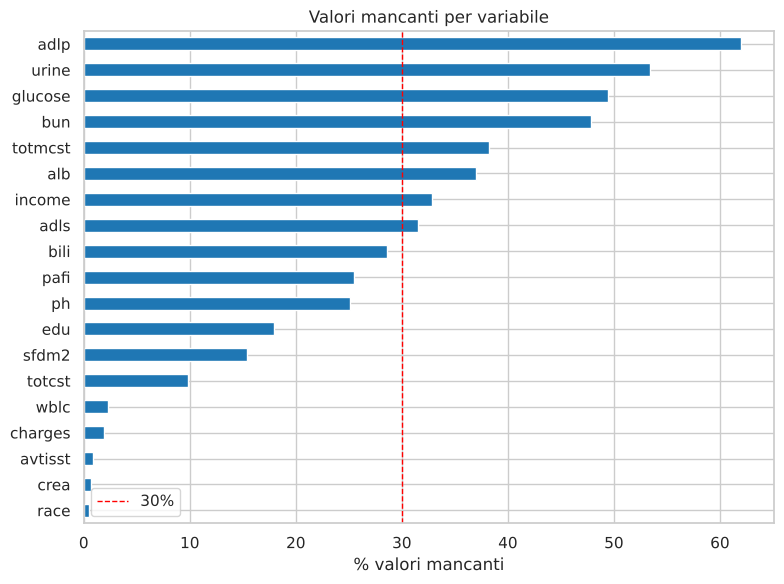

In [4]:
missing = (data_ok.isna().mean() * 100).round(1)
missing = missing[missing > 0].sort_values(ascending=False)
print("Variabili con valori mancanti:", len(missing), "su", data_ok.shape[1])

fig, ax = plt.subplots(figsize=(8, 6))
missing.sort_values().plot.barh(ax=ax, color="tab:blue")
ax.axvline(30, color="red", ls="--", lw=1, label="30%")
ax.set_xlabel("% valori mancanti")
ax.set_title("Valori mancanti per variabile")
ax.legend()
plt.tight_layout()
plt.show()

### 2.3 Distribuzione delle variabili numeriche

Un istogramma per variabile, con l'asimmetria (*skewness*) nel titolo, per individuare variabili molto sbilanciate o con outlier.

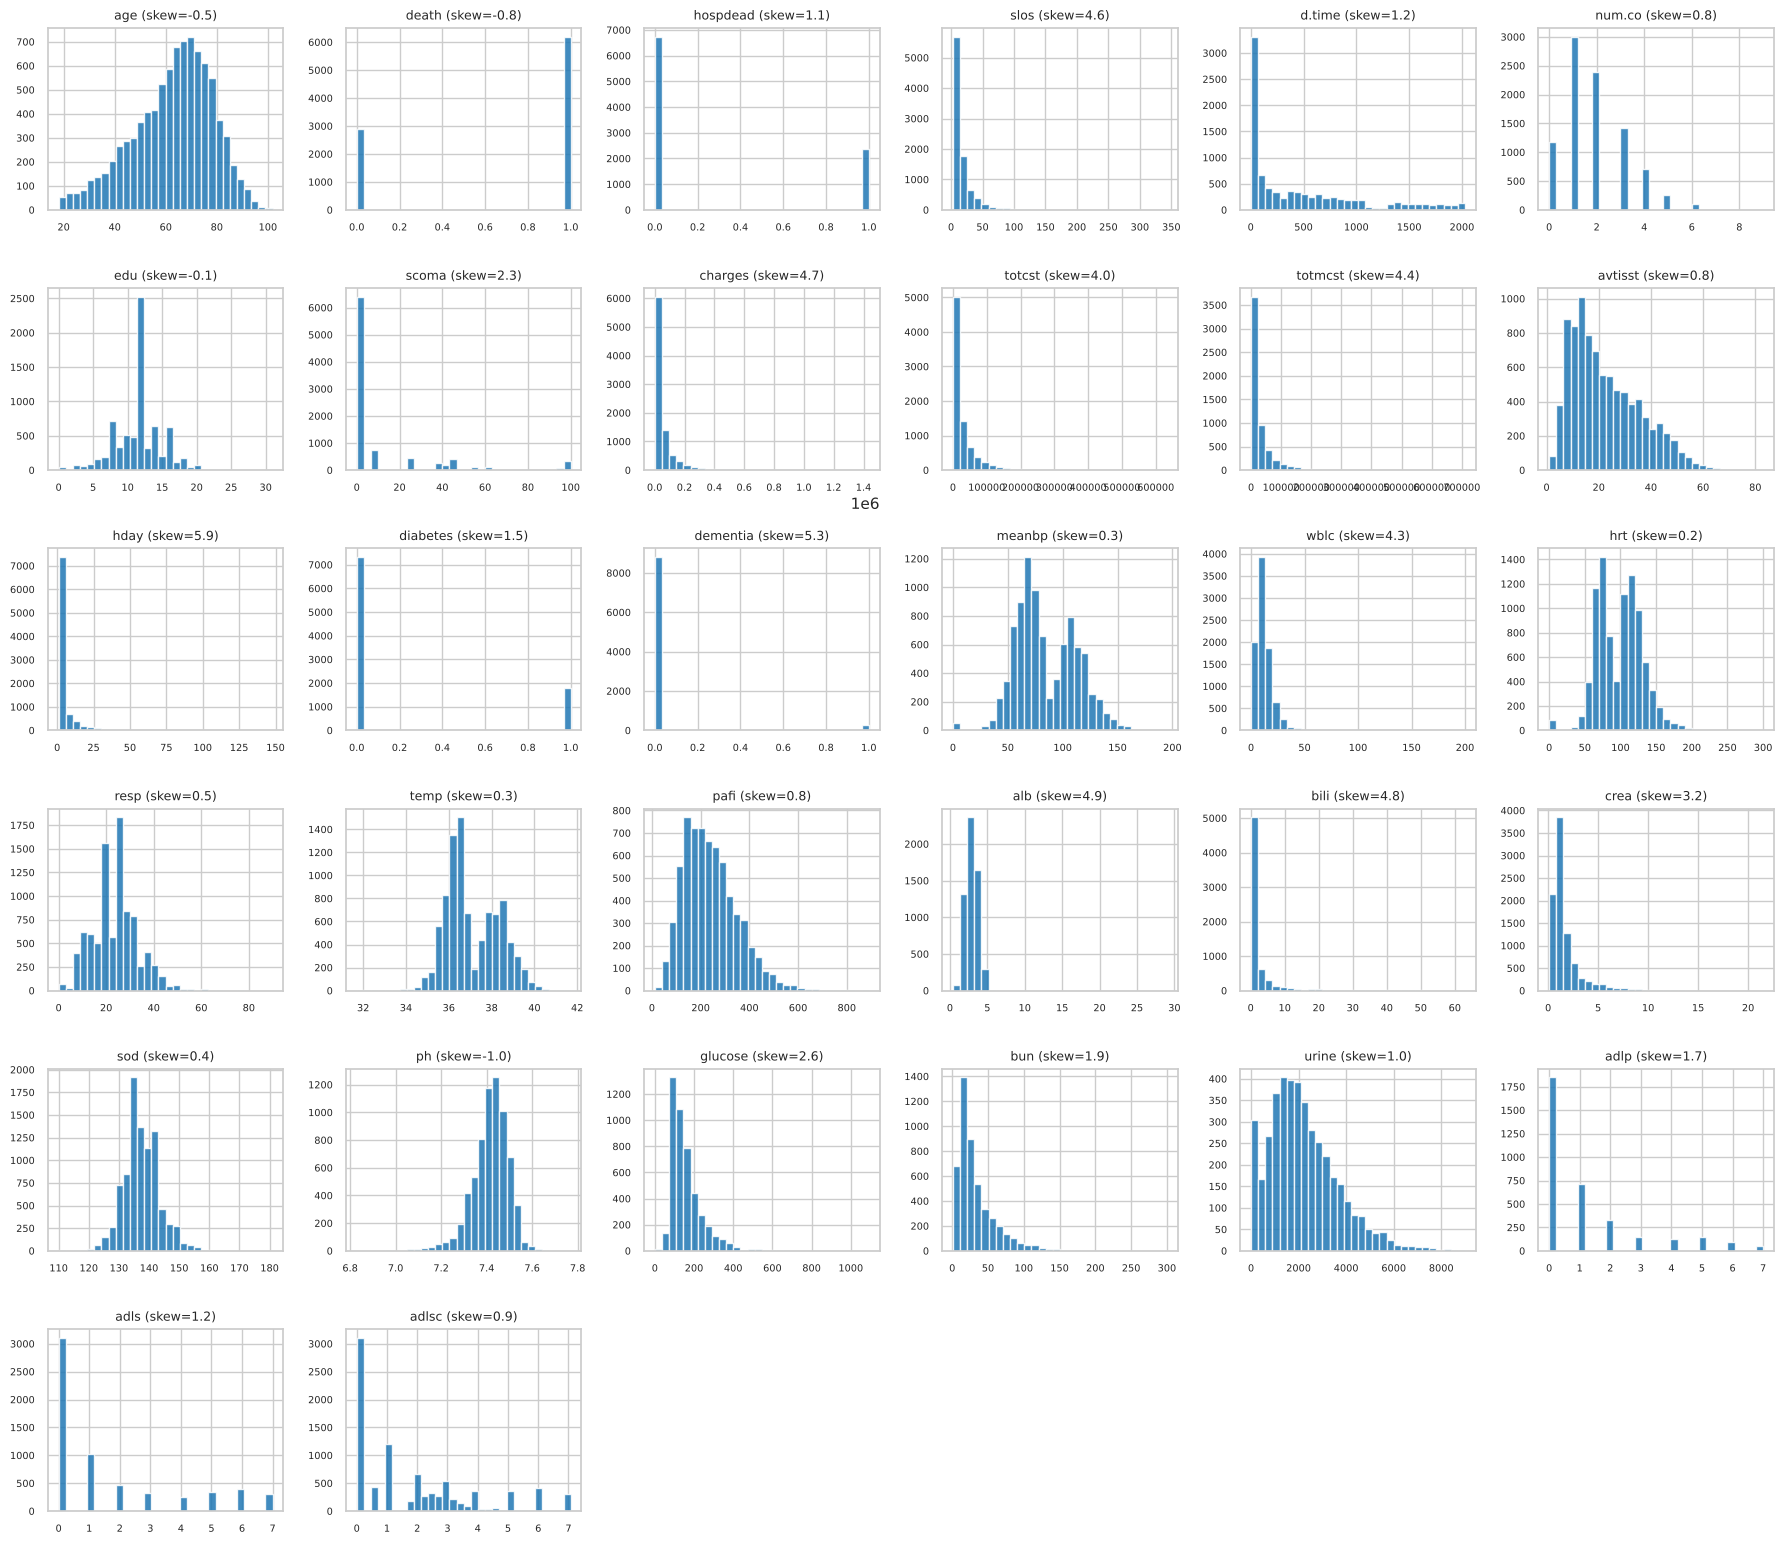

In [5]:
num_cols_eda = data_ok.select_dtypes(include="number").columns.tolist()
n = len(num_cols_eda)
ncols = 6
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 2.6 * nrows))
for ax, col in zip(axes.ravel(), num_cols_eda):
    ax.hist(data_ok[col].dropna(), bins=30, color="tab:blue", alpha=0.85)
    ax.set_title(f"{col} (skew={data_ok[col].skew():.1f})", fontsize=9)
    ax.tick_params(labelsize=7)
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 2.4 La variabile target della regressione: `totcst`

Guardiamo la distribuzione del costo totale, in scala originale e logaritmica, e come varia per gruppo diagnostico.

totcst: valori validi = 8217, mancanti = 888 (9.8%)
media = 30,826   mediana = 14,453   dev.std = 45,781   skewness = 3.96
valori pari a zero: 17


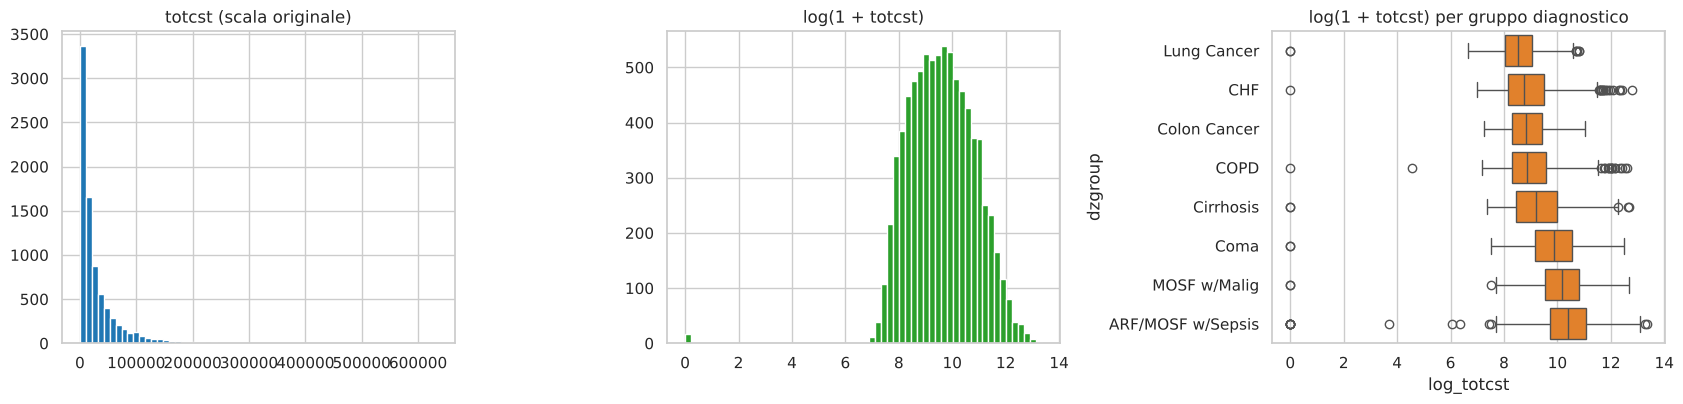

In [6]:
t = data_ok["totcst"]
print(f"totcst: valori validi = {t.notna().sum()}, mancanti = {t.isna().sum()} ({t.isna().mean():.1%})")
print(f"media = {t.mean():,.0f}   mediana = {t.median():,.0f}   dev.std = {t.std():,.0f}   skewness = {t.skew():.2f}")
print(f"valori pari a zero: {(t == 0).sum()}")

tmp = data_ok.assign(log_totcst=np.log1p(data_ok["totcst"]))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
axes[0].hist(t.dropna(), bins=60, color="tab:blue")
axes[0].set_title("totcst (scala originale)")
axes[1].hist(tmp["log_totcst"].dropna(), bins=60, color="tab:green")
axes[1].set_title("log(1 + totcst)")
order = tmp.groupby("dzgroup")["log_totcst"].median().sort_values().index
sns.boxplot(data=tmp, y="dzgroup", x="log_totcst", order=order, ax=axes[2], color="tab:orange")
axes[2].set_title("log(1 + totcst) per gruppo diagnostico")
plt.tight_layout()
plt.show()

### 2.5 Correlazioni

Matrice di correlazione tra tutte le variabili numeriche (correlazione di Pearson calcolata sulle coppie di valori disponibili), poi l'elenco delle coppie più correlate e infine le variabili più correlate con il target della regressione `totcst`.

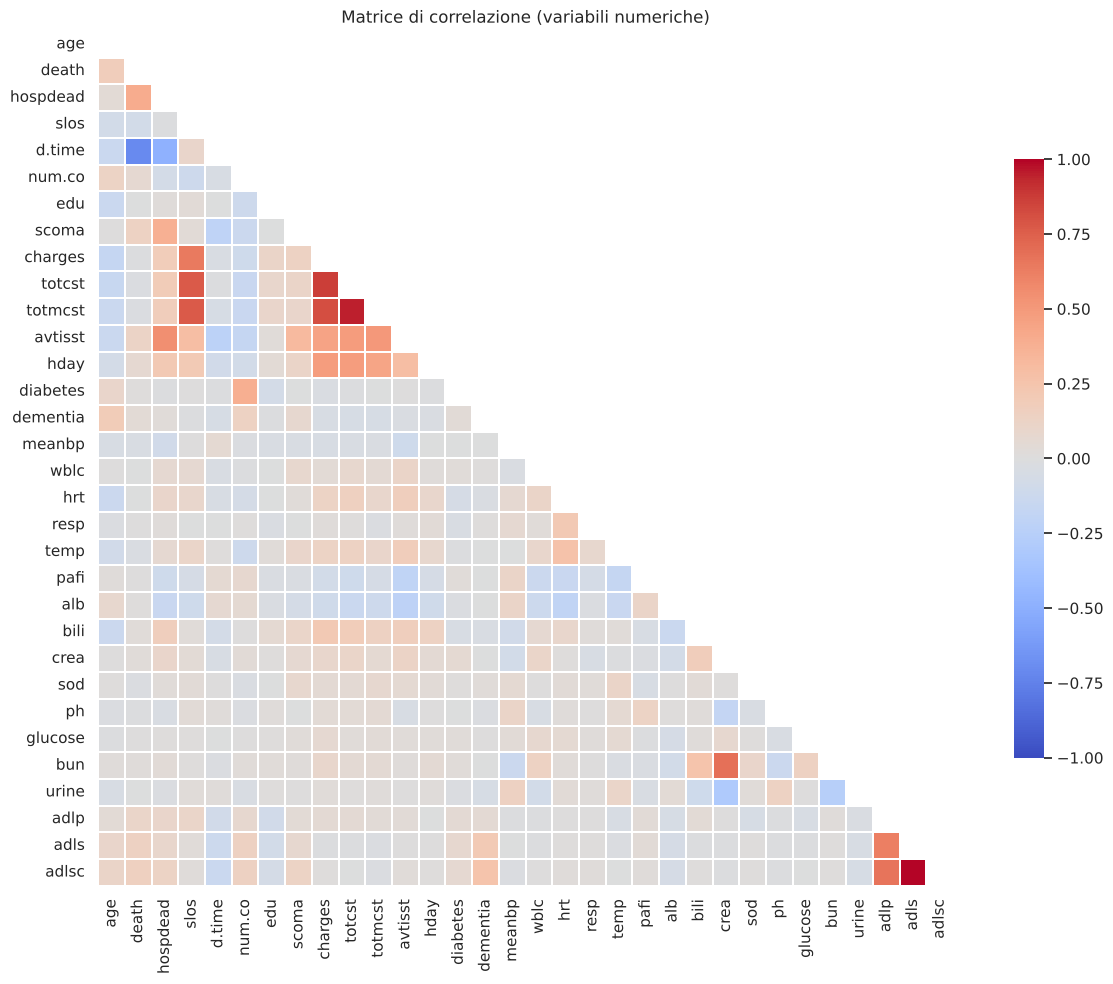

Coppie di variabili con |r| > 0.6:


,var1,var2,r
0,adlsc,adls,1.00
1,totmcst,totcst,0.95
2,totcst,charges,0.87
3,totmcst,charges,0.81
4,totcst,slos,0.77
5,totmcst,slos,0.77
6,d.time,death,-0.71
7,bun,crea,0.68
8,adlsc,adlp,0.67
9,charges,slos,0.64


In [7]:
corr = data_ok[num_cols_eda].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(13, 10))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.3, cbar_kws={"shrink": 0.7})
plt.gca().grid(False)
plt.title("Matrice di correlazione (variabili numeriche)")
plt.tight_layout()
plt.show()

ii, jj = np.tril_indices_from(corr, k=-1)
pairs = pd.DataFrame({"var1": corr.index[ii], "var2": corr.columns[jj], "r": corr.values[ii, jj]})
print("Coppie di variabili con |r| > 0.6:")
display(pairs[pairs["r"].abs() > 0.6].sort_values("r", key=abs, ascending=False).round(2).reset_index(drop=True))

Variabili più correlate con totcst:


,Pearson,Spearman
totmcst,0.949,0.954
charges,0.872,0.973
slos,0.772,0.775
avtisst,0.486,0.703
hday,0.479,0.603
hospdead,0.192,0.286
bili,0.181,0.205
age,-0.155,-0.151
hrt,0.152,0.187
num.co,-0.148,-0.227


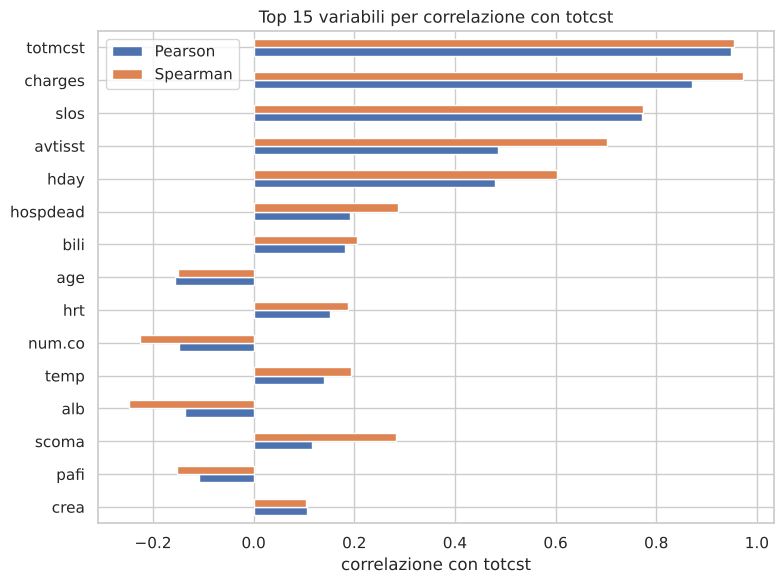

In [8]:
cor_target = pd.DataFrame({
    "Pearson": data_ok[num_cols_eda].corr()["totcst"],
    "Spearman": data_ok[num_cols_eda].corr(method="spearman")["totcst"],
}).drop("totcst")
cor_target = cor_target.reindex(cor_target["Pearson"].abs().sort_values(ascending=False).index)
print("Variabili più correlate con totcst:")
display(cor_target.head(12).round(3))

top = cor_target.head(15).iloc[::-1]
ax = top.plot.barh(figsize=(8, 6))
ax.set_xlabel("correlazione con totcst")
ax.set_title("Top 15 variabili per correlazione con totcst")
plt.tight_layout()
plt.show()

### 2.6 Distribuzione delle classi per la classificazione

Il target della classificazione sarà `death`. Controlliamo quanto è bilanciato, come varia per gruppo diagnostico e, soprattutto, **come si relaziona con `hospdead` e `sfdm2`**, che potrebbero contenere già l'esito.

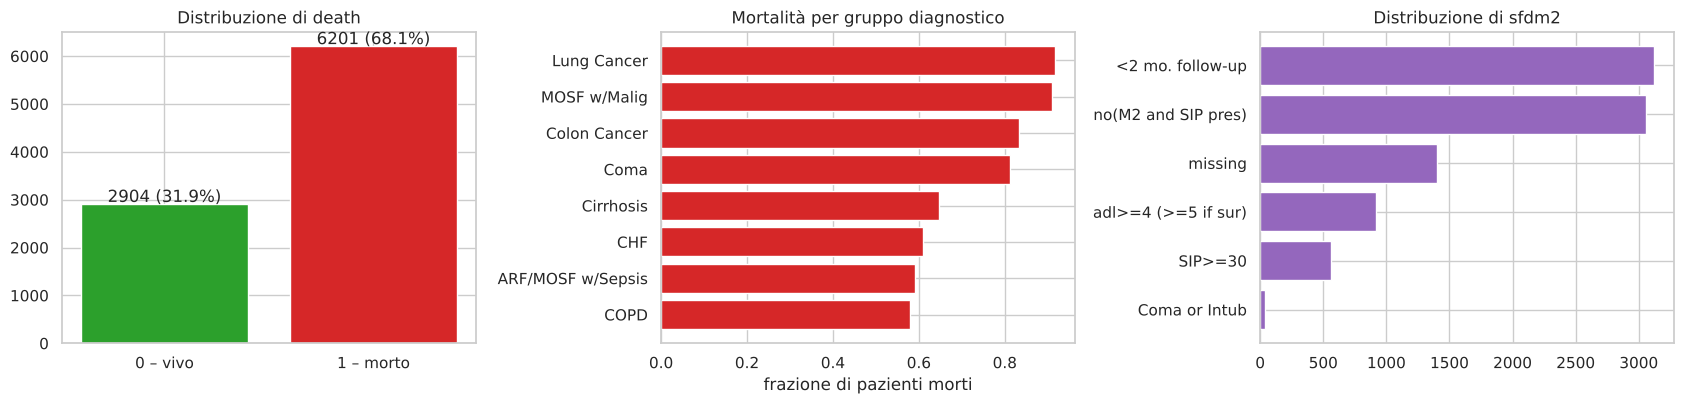

death x hospdead (hospdead = morte in ospedale):


death,0,1
hospdead,,
0,2904,3841
1,0,2360


sfdm2 x death:


death,0,1
sfdm2,,
<2 mo. follow-up,0,3123
Coma or Intub,9,32
SIP>=30,268,296
adl>=4 (>=5 if sur),358,558
missing,596,804
no(M2 and SIP pres),1673,1388


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
counts = data_ok["death"].value_counts().sort_index()
bars = axes[0].bar(["0 – vivo", "1 – morto"], counts.values, color=["tab:green", "tab:red"])
for b, v in zip(bars, counts.values):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 50, f"{v} ({v / len(data_ok):.1%})", ha="center")
axes[0].set_title("Distribuzione di death")

dz = pd.crosstab(data_ok["dzgroup"], data_ok["death"], normalize="index")[1].sort_values()
axes[1].barh(dz.index, dz.values, color="tab:red")
axes[1].set_xlabel("frazione di pazienti morti")
axes[1].set_title("Mortalità per gruppo diagnostico")

sf = data_ok["sfdm2"].fillna("missing").value_counts().sort_values()
axes[2].barh(sf.index, sf.values, color="tab:purple")
axes[2].set_title("Distribuzione di sfdm2")
plt.tight_layout()
plt.show()

print("death x hospdead (hospdead = morte in ospedale):")
display(pd.crosstab(data_ok["hospdead"], data_ok["death"]))
print("sfdm2 x death:")
display(pd.crosstab(data_ok["sfdm2"].fillna("missing"), data_ok["death"]))

### 2.7 Visualizzazione di campioni

Scatter plot tra le variabili più rilevanti (campione casuale di 1500 pazienti, scala logaritmica per costi e degenza), colorati per esito.

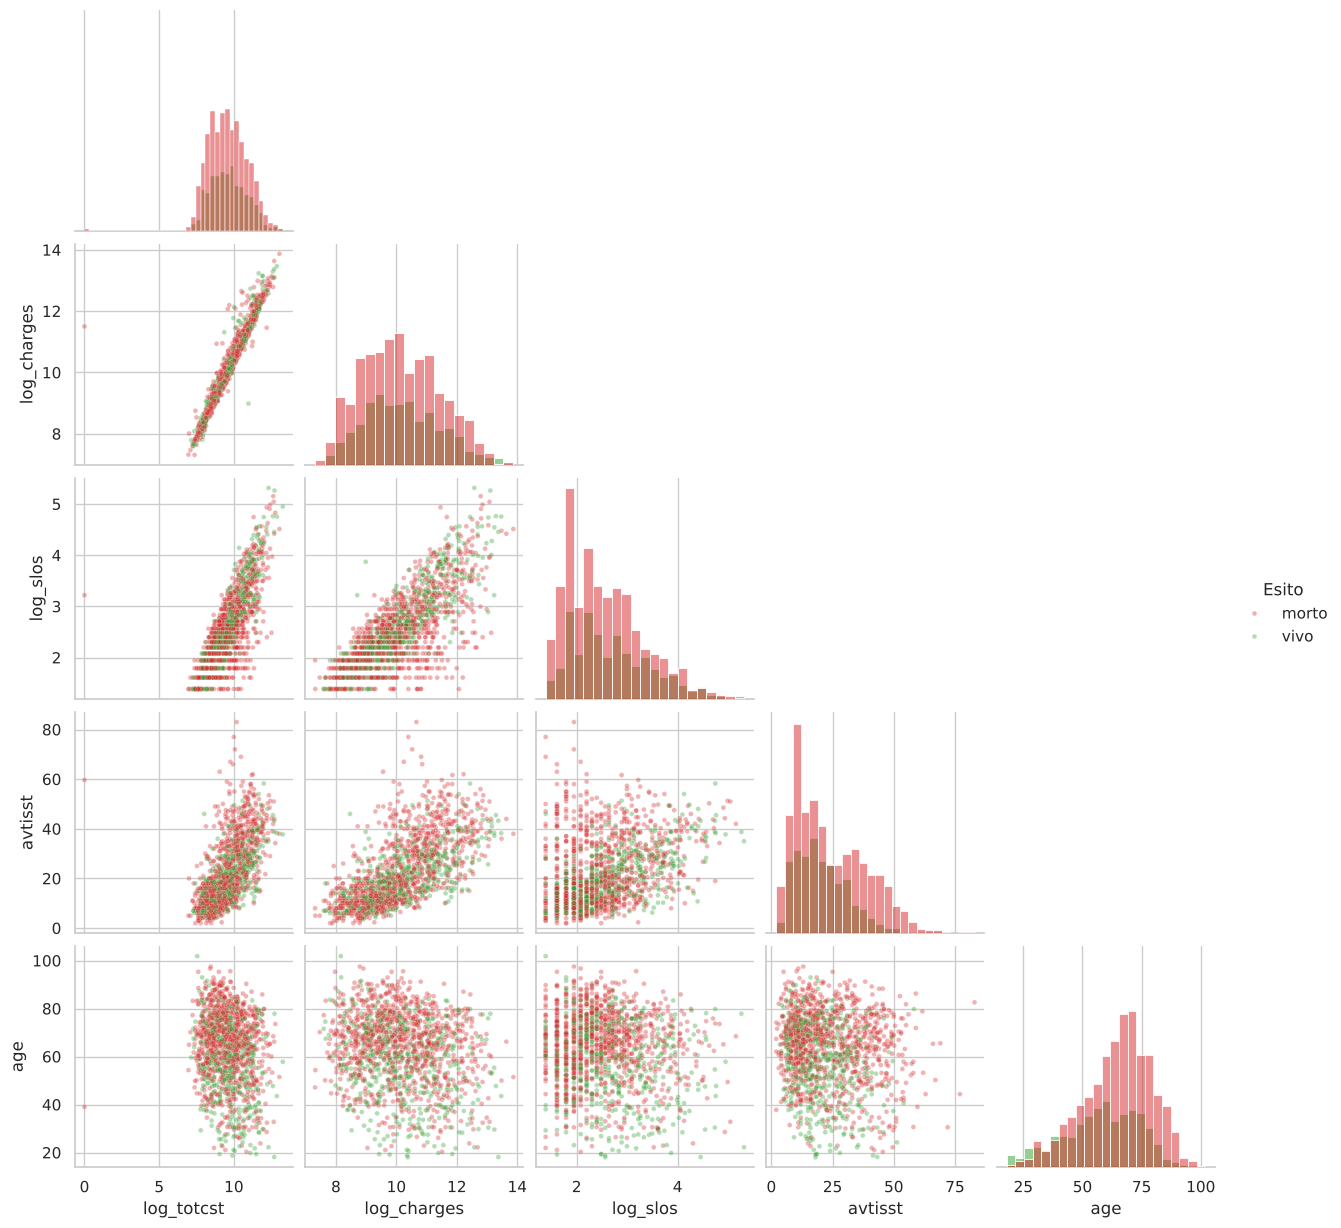

In [10]:
sample = data_ok.sample(1500, random_state=RANDOM_STATE).copy()
for c in ["totcst", "charges", "slos"]:
    sample["log_" + c] = np.log1p(sample[c])
sample["Esito"] = sample["death"].map({0: "vivo", 1: "morto"})
g = sns.pairplot(sample, vars=["log_totcst", "log_charges", "log_slos", "avtisst", "age"], hue="Esito",
                 corner=True, plot_kws={"alpha": 0.35, "s": 12}, diag_kind="hist",
                 palette={"vivo": "tab:green", "morto": "tab:red"})
plt.show()

## 3. Preprocessing comune ai tre task

Prima di dividere in train e test facciamo solo trasformazioni **che non dipendono dai dati**:

- **Valori di riferimento della consegna (Table 1)** per `alb`, `pafi`, `bili`, `crea`, `bun`, `wblc`, `urine`: sono costanti cliniche "normali", quindi non c'è alcuna fuga di informazione.
- **Variabili categoriche** (`sex`, `dzgroup`, `dzclass`, `income`, `race`, `ca`): i mancanti diventano una categoria esplicita `"missing"` (soprattutto `income` ne ha il 33%, e il fatto che manchi può essere informativo).
- **`adlp` e `adls`** vengono sostituite da `adlsc`. `adlsc` è la versione "calibrata" e completa dello stesso punteggio ADL: dove `adls` è osservato i due valori coincidono (lo verifichiamo qui sotto), mentre `adlp` e `adls` hanno il 62% e il 31% di mancanti. Tenerle tutte e tre vorrebbe dire duplicare l'informazione e imputare molto.

Tutte le altre imputazioni (mediana per le numeriche rimaste) e la standardizzazione vengono fatte **dentro le pipeline**, fittate solo sul training set.

In [11]:
FILL_IN = {"alb": 3.5, "pafi": 333.3, "bili": 1.01, "crea": 1.01, "bun": 6.51, "wblc": 9.0, "urine": 2502}
CAT_COLS = ["sex", "dzgroup", "dzclass", "income", "race", "ca"]

base = data_ok.copy()
for col, val in FILL_IN.items():
    n_fill = int(base[col].isna().sum())
    base[col] = base[col].fillna(val)
    print(f"{col:6s}: {n_fill:4d} valori mancanti riempiti con {val}")
for col in CAT_COLS:
    base[col] = base[col].fillna("missing")

# adlp / adls vs adlsc
same = (base["adls"] == base["adlsc"])[base["adls"].notna()].mean()
print(f"\nadlsc coincide con adls nel {same:.1%} dei casi in cui adls è osservato")
print(f"mancanti: adlp {base['adlp'].isna().mean():.1%}, adls {base['adls'].isna().mean():.1%}, adlsc {base['adlsc'].isna().mean():.1%}")
print(f"correlazione tra adlsc e adlp: {base[['adlsc', 'adlp']].corr().iloc[0, 1]:.2f}")
base = base.drop(columns=["adlp", "adls"])
print("\nDimensioni del dataset di base:", base.shape)
print("Mancanti rimasti (verranno imputati nelle pipeline):", int(base.drop(columns=["totcst"]).isna().sum().sum()), "celle")

alb   : 3372 valori mancanti riempiti con 3.5
pafi  : 2325 valori mancanti riempiti con 333.3
bili  : 2601 valori mancanti riempiti con 1.01
crea  :   67 valori mancanti riempiti con 1.01
bun   : 4352 valori mancanti riempiti con 6.51
wblc  :  212 valori mancanti riempiti con 9.0
urine : 4862 valori mancanti riempiti con 2502

adlsc coincide con adls nel 100.0% dei casi in cui adls è osservato
mancanti: adlp 62.0%, adls 31.5%, adlsc 0.0%
correlazione tra adlsc e adlp: 0.67

Dimensioni del dataset di base: (9105, 37)
Mancanti rimasti (verranno imputati nelle pipeline): 13553 celle


In [12]:
from sklearn.base import clone


def split_cols(X):
    """Separa colonne categoriche e numeriche."""
    cat = [c for c in X.columns if c in CAT_COLS + ["sfdm2"]]
    num = [c for c in X.columns if c not in cat]
    return num, cat


def make_preprocessor(X):
    """Mediana + standardizzazione per le numeriche, one-hot per le categoriche.
    Viene fittato solo sui dati passati a fit (cioè il training set / il training fold)."""
    num, cat = split_cols(X)
    return ColumnTransformer(
        [("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num),
         ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)],
        verbose_feature_names_out=False)


def make_pipe(X, model):
    return Pipeline([("prep", make_preprocessor(X)), ("model", model)])

## 4. Regressione: stima del costo totale `totcst`

### 4.1 Impostazione del problema e scelta delle variabili

**Target.** `totcst` è mancante per 888 pazienti: un target non si imputa, quindi si scartano quelle righe.

**Quali variabili usare come predittori?** Qui serve ragionare sul dominio, perché alcune colonne sono già una misura del costo:

- `death`, `d.time`, `sfdm2` descrivono ciò che accade **dopo** la dimissione (morte fino al 1994, giorni di follow-up, disabilità a 2 mesi): non hanno senso per stimare il costo di un ricovero e le togliamo.
- `charges` (importo fatturato) e `totmcst` (costo calcolato dalle singole voci) sono **misure alternative dello stesso costo**: `totcst` è il costo stimato moltiplicando la fattura per un rapporto costi/ricavi, e `totmcst` è un'altra stima dello stesso importo. Includerle significa "predire il costo con il costo".

Per non nascondere l'effetto di questa scelta confrontiamo due scenari con gli stessi pazienti e lo stesso split:

- **Scenario A** – tutte le variabili ammesse, compresi `charges` e `totmcst`;
- **Scenario B** – senza `charges` e `totmcst`: l'unica analisi che risponde davvero alla domanda "quali caratteristiche del paziente e del ricovero spiegano il costo?". **È lo scenario su cui facciamo tuning, feature selection e diagnostica.**

In [13]:
reg = base.dropna(subset=["totcst"]).copy()
print(f"Pazienti con totcst osservato: {len(reg)} su {len(base)} (scartati {len(base) - len(reg)})")

AFTER_DISCHARGE = ["death", "d.time", "sfdm2"]
COST_PROXIES = ["charges", "totmcst"]

y = reg["totcst"]
X_A = reg.drop(columns=["totcst"] + AFTER_DISCHARGE)   # scenario A
X_B = X_A.drop(columns=COST_PROXIES)                    # scenario B
print(f"Scenario A: {X_A.shape[1]} predittori   |   Scenario B: {X_B.shape[1]} predittori")

print("\nQuanto sono 'costo' charges e totmcst?")
print(f"  correlazione di Pearson con totcst: charges {reg['totcst'].corr(reg['charges']):.3f}, totmcst {reg['totcst'].corr(reg['totmcst']):.3f}")
ratio = (reg["totcst"] / reg["charges"]).dropna()
print(f"  rapporto totcst/charges: mediana {ratio.median():.2f}, 25°-75° percentile {ratio.quantile(.25):.2f}-{ratio.quantile(.75):.2f}")

# split unico (stessi pazienti in A e in B)
idx_train, idx_test = train_test_split(reg.index, test_size=0.2, random_state=RANDOM_STATE)
y_tr, y_te = y.loc[idx_train], y.loc[idx_test]
print(f"\nTraining: {len(idx_train)} pazienti   Test: {len(idx_test)} pazienti")

cv5 = KFold(5, shuffle=True, random_state=RANDOM_STATE)

Pazienti con totcst osservato: 8217 su 9105 (scartati 888)
Scenario A: 33 predittori   |   Scenario B: 31 predittori

Quanto sono 'costo' charges e totmcst?
  correlazione di Pearson con totcst: charges 0.872, totmcst 0.949
  rapporto totcst/charges: mediana 0.64, 25°-75° percentile 0.56-0.69

Training: 6573 pazienti   Test: 1644 pazienti


### 4.2 Scelta della trasformazione del target

`totcst` è molto asimmetrica (skewness ≈ 4): pochi ricoveri costosissimi dominano gli errori quadratici. È naturale chiedersi se convenga modellare `log(1 + totcst)` e poi tornare in dollari. Lo verifichiamo invece di darlo per scontato: cross-validation sul training (scenario B) per regressione lineare e Random Forest, con target grezzo e con target logaritmico, riportando sempre le metriche **in dollari**.

CV R2 ($)  CV R2 std  CV RMSE ($)  CV MAE ($)
Modello           Target                                                    
Linear Regression grezzo           0.757      0.035      22170.0     11558.0
                  logaritmico  -1031.030   1917.151     957258.0     51939.0
Random Forest     grezzo           0.769      0.018      21695.0      9725.0
                  logaritmico      0.726      0.017      23586.0      9589.0

Regressione lineare con target logaritmico, test set: previsione massima = 189,786,454 $, costo reale massimo = 473,212 $
Pazienti con costo totale < 500 $: 20 (di cui 17 con costo esattamente 0) nonostante fatture mediane di 45,422 $


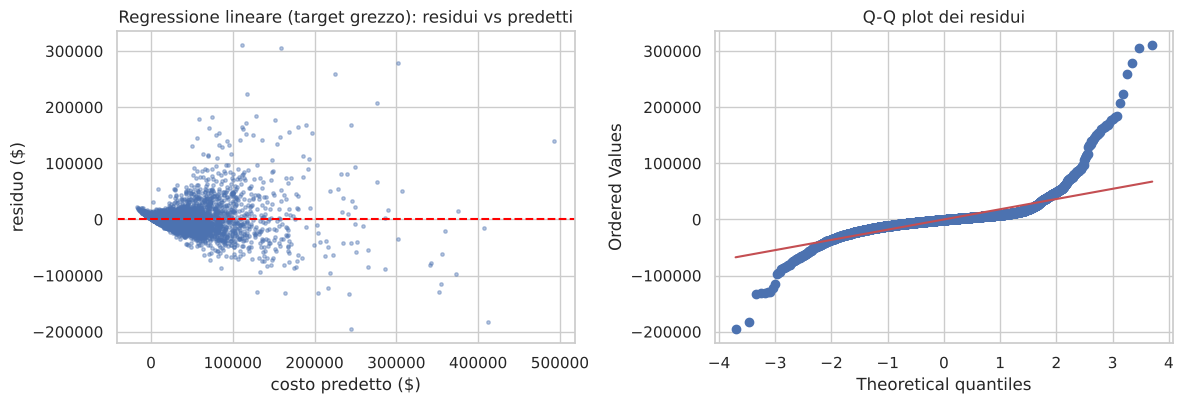

In [14]:
Xtr_B, Xte_B = X_B.loc[idx_train], X_B.loc[idx_test]
scoring = {"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"}

rows, res_fit = [], {}
candidates = {"Linear Regression": LinearRegression(),
              "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=3, max_features=0.5,
                                                      n_jobs=-1, random_state=RANDOM_STATE)}
for name, est in candidates.items():
    for tgt in ["grezzo", "logaritmico"]:
        pipe = make_pipe(Xtr_B, clone(est))
        model = pipe if tgt == "grezzo" else TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)
        cvr = cross_validate(model, Xtr_B, y_tr, cv=cv5, scoring=scoring)
        rows.append({"Modello": name, "Target": tgt, "CV R2 ($)": cvr["test_r2"].mean(), "CV R2 std": cvr["test_r2"].std(),
                     "CV RMSE ($)": -cvr["test_rmse"].mean(), "CV MAE ($)": -cvr["test_mae"].mean()})
        res_fit[(name, tgt)] = model.fit(Xtr_B, y_tr)
target_cmp = pd.DataFrame(rows).set_index(["Modello", "Target"])
display(target_cmp.round({"CV R2 ($)": 3, "CV R2 std": 3, "CV RMSE ($)": 0, "CV MAE ($)": 0}))

p_log = res_fit[("Linear Regression", "logaritmico")].predict(Xte_B)
print(f"Regressione lineare con target logaritmico, test set: previsione massima = {p_log.max():,.0f} $, "
      f"costo reale massimo = {y_te.max():,.0f} $")
n_low = int((y < 500).sum())
print(f"Pazienti con costo totale < 500 $: {n_low} (di cui {int((y == 0).sum())} con costo esattamente 0) "
      f"nonostante fatture mediane di {reg.loc[y < 500, 'charges'].median():,.0f} $")

m = res_fit[("Linear Regression", "grezzo")]
pred = m.predict(Xtr_B)
res = y_tr - pred
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].scatter(pred, res, s=6, alpha=0.4)
axes[0].axhline(0, color="red", ls="--")
axes[0].set_xlabel("costo predetto ($)")
axes[0].set_ylabel("residuo ($)")
axes[0].set_title("Regressione lineare (target grezzo): residui vs predetti")
stats.probplot(res, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot dei residui")
plt.tight_layout()
plt.show()

**Commento.** Il logaritmo del target **non conviene**, e il confronto lo mostra:

- con il **target grezzo** la regressione lineare ottiene un R² medio in cross-validation di 0.757. Con il target logaritmico, riportato in dollari, lo stesso modello produce per alcuni pazienti previsioni assurde (nel test la previsione massima è di circa 190 milioni di dollari, contro un costo reale massimo di 473 mila): l'esponenziale amplifica gli errori della retta nella coda e l'R² medio crolla;
- per la Random Forest il R² scende da 0.769 a 0.726, mentre l'errore assoluto medio resta praticamente uguale (9725 \$ contro 9589 \$).

Lavoriamo quindi sul **costo grezzo** e valutiamo tutto in dollari.

Due note sui dati. Venti pazienti hanno un costo totale inferiore a 500 \$ (17 esattamente 0) pur avendo fatture mediane di oltre 45 mila \$: sono probabilmente costi non registrati. Li teniamo, perché non possiamo dimostrare che siano errori, ma sono tra gli outlier più grandi dei residui (nella scala logaritmica avrebbero un peso enorme, perché log(1+0) = 0). Inoltre il grafico dei residui del modello lineare mostra una varianza degli errori che cresce con il costo previsto (andamento "a imbuto") e code molto più pesanti di una normale: le ipotesi classiche della regressione lineare (errori omoschedastici e normali) non sono rispettate. I p-value calcolati più avanti vanno quindi letti come indicativi, e il confronto tra modelli si basa soprattutto sulla validazione.

### 4.3 Confronto tra algoritmi di regressione

Confrontiamo nove algoritmi, dal baseline banale (`Dummy`, predice sempre la media) ai modelli lineari regolarizzati, ai metodi non lineari (KNN, albero, Random Forest, Gradient Boosting). Per ognuno: R², RMSE e MAE in dollari, con cross-validation a 5 fold sul training (media e deviazione standard dell'R²) e valutazione sul test set. Il confronto è fatto per entrambi gli scenari, A e B. Tutti i modelli stanno in una pipeline con imputazione, standardizzazione e one-hot, fittata sul solo training (o training fold).

In [15]:
def evaluate_reg(name, pipe, X_tr, y_tr, X_te, y_te, cv=cv5):
    """Cross-validation sul training, poi fit sul training e valutazione su train e test (scala originale, $)."""
    cvr = cross_validate(pipe, X_tr, y_tr, cv=cv, scoring=scoring)
    pipe.fit(X_tr, y_tr)
    p_tr, p_te = pipe.predict(X_tr), pipe.predict(X_te)
    return {"Model": name, "CV R2": cvr["test_r2"].mean(), "CV R2 std": cvr["test_r2"].std(),
            "CV RMSE": -cvr["test_rmse"].mean(), "Train R2": r2_score(y_tr, p_tr),
            "Test R2": r2_score(y_te, p_te), "Test RMSE": float(np.sqrt(mean_squared_error(y_te, p_te))),
            "Test MAE": mean_absolute_error(y_te, p_te)}


def reg_models():
    return {
        "Dummy (media)": DummyRegressor(strategy="mean"),
        "Linear Regression": LinearRegression(),
        "Ridge (alpha=1)": Ridge(alpha=1.0),
        "Lasso (alpha=1)": Lasso(alpha=1.0, max_iter=50000),
        "ElasticNet (alpha=1)": ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=50000),
        "KNN (k=15)": KNeighborsRegressor(n_neighbors=15),
        "Decision Tree (depth=6)": DecisionTreeRegressor(max_depth=6, random_state=RANDOM_STATE),
        "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=3, max_features=0.5,
                                               n_jobs=-1, random_state=RANDOM_STATE),
        "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, max_depth=3, random_state=RANDOM_STATE),
    }


def compare_regressors(X):
    rows = [evaluate_reg(n, make_pipe(X, est), X.loc[idx_train], y_tr, X.loc[idx_test], y_te)
            for n, est in reg_models().items()]
    return pd.DataFrame(rows).set_index("Model")


def show_reg(df):
    return df.round({"CV R2": 3, "CV R2 std": 3, "CV RMSE": 0, "Train R2": 3, "Test R2": 3, "Test RMSE": 0, "Test MAE": 0})


res_A = compare_regressors(X_A)
print("SCENARIO A – tutte le variabili ammesse (con charges e totmcst)")
display(show_reg(res_A))

res_B = compare_regressors(X_B)
print("SCENARIO B – senza charges e totmcst")
display(show_reg(res_B))

SCENARIO A – tutte le variabili ammesse (con charges e totmcst)


,CV R2,CV R2 std,CV RMSE,Train R2,Test R2,Test RMSE,Test MAE
Model,,,,,,,
Dummy (media),-0.001,0.000,45154.0,0.000,-0.000,48021.0,28803.0
Linear Regression,0.841,0.031,17868.0,0.853,0.859,18048.0,8166.0
Ridge (alpha=1),0.841,0.031,17867.0,0.853,0.859,18047.0,8165.0
Lasso (alpha=1),0.841,0.031,17866.0,0.853,0.859,18047.0,8163.0
ElasticNet (alpha=1),0.816,0.019,19294.0,0.821,0.836,19421.0,8620.0
KNN (k=15),0.758,0.022,22158.0,0.799,0.792,21919.0,11626.0
Decision Tree (depth=6),0.884,0.019,15376.0,0.954,0.878,16785.0,6042.0
Random Forest,0.924,0.007,12401.0,0.974,0.927,12969.0,3801.0
Gradient Boosting,0.926,0.012,12222.0,0.975,0.919,13664.0,4658.0


SCENARIO B – senza charges e totmcst


,CV R2,CV R2 std,CV RMSE,Train R2,Test R2,Test RMSE,Test MAE
Model,,,,,,,
Dummy (media),-0.001,0.000,45154.0,0.000,-0.000,48021.0,28803.0
Linear Regression,0.757,0.035,22170.0,0.763,0.744,24270.0,11942.0
Ridge (alpha=1),0.757,0.035,22170.0,0.763,0.744,24271.0,11941.0
Lasso (alpha=1),0.757,0.035,22170.0,0.763,0.744,24272.0,11940.0
ElasticNet (alpha=1),0.701,0.032,24631.0,0.704,0.683,27011.0,12557.0
KNN (k=15),0.605,0.036,28311.0,0.667,0.599,30416.0,14728.0
Decision Tree (depth=6),0.648,0.027,26761.0,0.818,0.667,27703.0,12169.0
Random Forest,0.769,0.018,21695.0,0.921,0.795,21737.0,9472.0
Gradient Boosting,0.769,0.022,21656.0,0.874,0.791,21925.0,10021.0


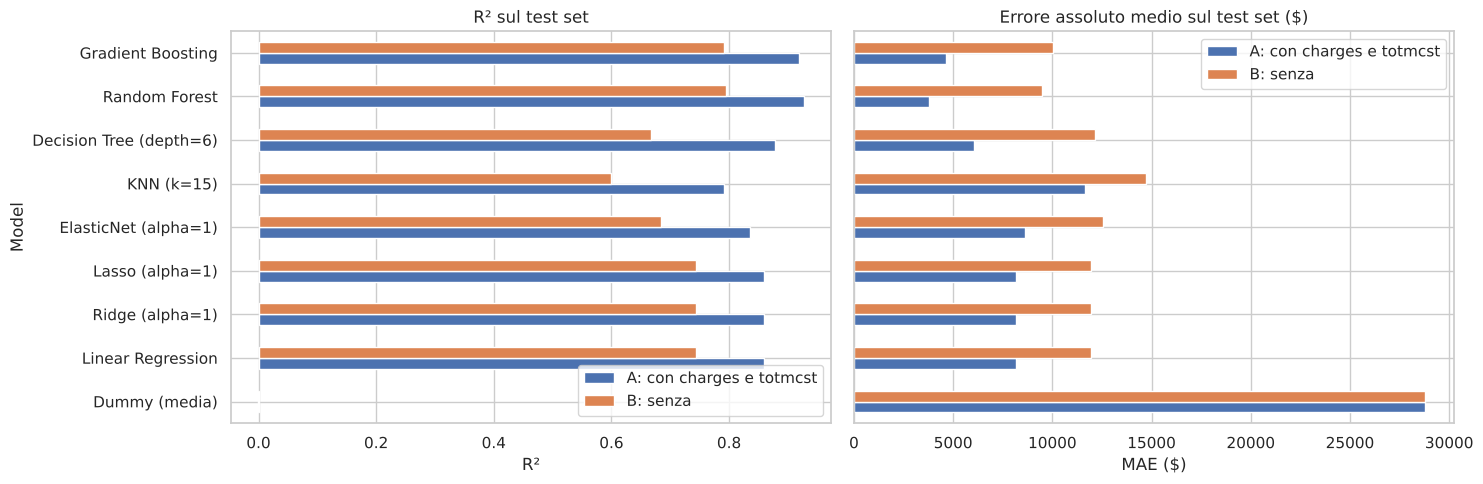

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
pd.DataFrame({"A: con charges e totmcst": res_A["Test R2"], "B: senza": res_B["Test R2"]}).plot.barh(ax=axes[0])
axes[0].set_title("R² sul test set")
axes[0].set_xlabel("R²")
pd.DataFrame({"A: con charges e totmcst": res_A["Test MAE"], "B: senza": res_B["Test MAE"]}).plot.barh(ax=axes[1])
axes[1].set_title("Errore assoluto medio sul test set ($)")
axes[1].set_xlabel("MAE ($)")
plt.tight_layout()
plt.show()

**Commento.**

- **Baseline.** Il `Dummy` ha R² ≈ 0 per costruzione: ogni modello deve batterlo, e tutti lo fanno.
- **Effetto delle variabili-proxy (A contro B).** Con `charges` e `totmcst` (scenario A) il R² sul test arriva a 0.93 con la Random Forest e a 0.86 con la regressione lineare. Senza (scenario B) scende a 0.80 e 0.74. Circa 0.12-0.13 punti di R² erano quindi "costo predetto con il costo": lo scenario B è quello informativo.
- **Scenario B.** Ridge e Lasso coincidono con la regressione lineare: il modello non è in overfitting (R² 0.763 sul training, 0.744 sul test) e la regolarizzazione non ha nulla da correggere. ElasticNet con `alpha` = 1 è un po' peggiore perché la penalità è troppo forte per questo target. KNN e albero singolo sono nettamente peggiori (R² sul test 0.60 e 0.67). Random Forest e Gradient Boosting sono i migliori (R² sul test 0.795 e 0.791, in cross-validation 0.769 entrambi), ma il vantaggio sul modello lineare in cross-validation (0.769 contro 0.757) è piccolo rispetto alla variabilità tra i fold (0.035). La Random Forest mostra un overfitting evidente (R² 0.92 sul training contro 0.77 in cross-validation), che però non peggiora il test.

### 4.4 Ottimizzazione degli iperparametri (scenario B)

Grid search con cross-validation **solo sul training set**, ottimizzando l'R². Per Ridge e Lasso la griglia di `alpha` è ampia, per controllare che l'ottimo non cada sul bordo. Per Random Forest e Gradient Boosting si usano griglie più piccole e 3 fold per contenere i tempi di calcolo.

Ridge              migliori parametri: {'alpha': 31.6228}   R² CV = 0.7566
Lasso              migliori parametri: {'alpha': 31.6228}   R² CV = 0.7566
Random Forest      migliori parametri: {'max_features': 0.6, 'min_samples_leaf': 3}   R² CV = 0.7597
Gradient Boosting  migliori parametri: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 250}   R² CV = 0.7584


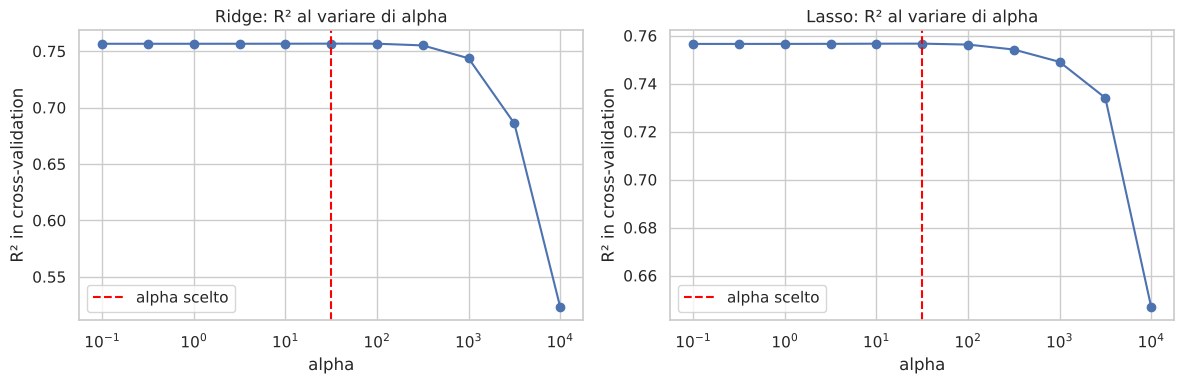

In [17]:
kf3 = KFold(3, shuffle=True, random_state=RANDOM_STATE)
grids = {
    "Ridge": (Ridge(), {"model__alpha": np.logspace(-1, 4, 11)}, cv5),
    "Lasso": (Lasso(max_iter=50000), {"model__alpha": np.logspace(-1, 4, 11)}, cv5),
    "Random Forest": (RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE),
                      {"model__max_features": [0.3, 0.6], "model__min_samples_leaf": [1, 3, 8]}, kf3),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=RANDOM_STATE),
                          {"model__n_estimators": [100, 250], "model__learning_rate": [0.05, 0.1],
                           "model__max_depth": [2, 4]}, kf3),
}
searches = {}
for name, (est, grid, cv) in grids.items():
    gs = GridSearchCV(make_pipe(Xtr_B, est), grid, cv=cv, scoring="r2", n_jobs=1 if "Forest" in name else -1)
    gs.fit(Xtr_B, y_tr)
    searches[name] = gs
    best = {k.replace("model__", ""): (round(float(v), 4) if isinstance(v, (float, np.floating)) else v)
            for k, v in gs.best_params_.items()}
    print(f"{name:18s} migliori parametri: {best}   R² CV = {gs.best_score_:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, ["Ridge", "Lasso"]):
    cvr = searches[name].cv_results_
    ax.semilogx(cvr["param_model__alpha"].astype(float), cvr["mean_test_score"], "o-")
    ax.axvline(searches[name].best_params_["model__alpha"], color="red", ls="--", label="alpha scelto")
    ax.set_xlabel("alpha")
    ax.set_ylabel("R² in cross-validation")
    ax.set_title(f"{name}: R² al variare di alpha")
    ax.legend()
plt.tight_layout()
plt.show()

In [18]:
tuned_rows, tuned = [], {}
for name in ["Ridge", "Lasso", "Random Forest", "Gradient Boosting"]:
    pipe = clone(searches[name].best_estimator_)
    tuned_rows.append(evaluate_reg(f"{name} (tuned)", pipe, Xtr_B, y_tr, Xte_B, y_te))
    tuned[f"{name} (tuned)"] = pipe
tuned_B = pd.DataFrame(tuned_rows).set_index("Model")
display(show_reg(tuned_B))

,CV R2,CV R2 std,CV RMSE,Train R2,Test R2,Test RMSE,Test MAE
Model,,,,,,,
Ridge (tuned),0.757,0.035,22167.0,0.763,0.744,24289.0,11920.0
Lasso (tuned),0.757,0.035,22166.0,0.763,0.743,24319.0,11906.0
Random Forest (tuned),0.767,0.015,21786.0,0.924,0.785,22249.0,9634.0
Gradient Boosting (tuned),0.765,0.027,21849.0,0.830,0.766,23223.0,10761.0


**Commento.** Per Ridge e Lasso il R² resta costante finché `alpha` è sotto circa 100 e crolla solo con penalità molto forti: l'`alpha` scelto (≈ 32) sta nel plateau e non sul bordo della griglia, ma non dà alcun guadagno rispetto a un `alpha` piccolo. Il tuning degli alberi non migliora in modo significativo i valori di partenza (R² in cross-validation 0.767 contro 0.769 per la Random Forest, 0.765 contro 0.769 per il Gradient Boosting): le differenze sono ben dentro la deviazione standard tra fold. Il limite sembra quindi stare nell'**informazione contenuta nelle variabili** (R² ≈ 0.76-0.77 per tutti i modelli ragionevoli) più che negli iperparametri.

### 4.5 Feature selection (scenario B)

Confrontiamo tre approcci, tutti addestrati **solo sul training set**:

1. **Forward selection** con regressione lineare: si parte da zero feature e a ogni passo si aggiunge quella che fa crescere di più l'R² in cross-validation. Scegliamo il numero di feature con la regola dell'*errore standard*: il modello più piccolo il cui R² è entro un errore standard dal massimo.
2. **Lasso**: la penalità L1 azzera i coefficienti delle feature poco utili (selezione "incorporata" nel modello).
3. **Permutation importance** della Random Forest: di quanto peggiora il modello quando si rimescola una variabile (calcolata sul test set, sulle colonne originali).

Feature dopo il preprocessing (one-hot incluso): 53
R² massimo con 20 feature (0.7574); regola dell'errore standard → 3 feature


,Passo,Feature aggiunta,CV R2,SE
0,1,slos,0.5937,0.0203
1,2,hday,0.7036,0.0203
2,3,avtisst,0.7423,0.0177
3,4,bili,0.7467,0.0167
4,5,income_under $11k,0.7494,0.0166
5,6,age,0.7510,0.0169
6,7,dzgroup_Coma,0.7522,0.0169
7,8,edu,0.7531,0.0167
8,9,hospdead,0.7540,0.0162
9,10,alb,0.7547,0.0160


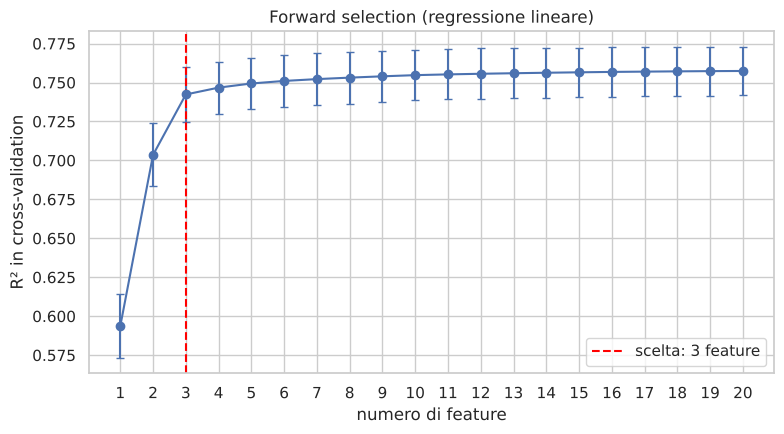

Feature selezionate: ['slos', 'hday', 'avtisst']


In [19]:
prep_B = make_preprocessor(Xtr_B)
feat_names = prep_B.fit(Xtr_B).get_feature_names_out()
Xtr_p = pd.DataFrame(prep_B.transform(Xtr_B), columns=feat_names, index=Xtr_B.index)
Xte_p = pd.DataFrame(prep_B.transform(Xte_B), columns=feat_names, index=Xte_B.index)
print("Feature dopo il preprocessing (one-hot incluso):", Xtr_p.shape[1])


def forward_selection(X, y, cv, max_features=20):
    selected, remaining, history = [], list(X.columns), []
    for _ in range(max_features):
        best = None
        for f in remaining:
            sc = cross_val_score(LinearRegression(), X[selected + [f]], y, cv=cv, scoring="r2")
            if best is None or sc.mean() > best[1]:
                best = (f, sc.mean(), sc.std() / np.sqrt(len(sc)))
        selected.append(best[0])
        remaining.remove(best[0])
        history.append({"Passo": len(selected), "Feature aggiunta": best[0], "CV R2": best[1], "SE": best[2]})
    return selected, pd.DataFrame(history)


fs_selected, fs_hist = forward_selection(Xtr_p, y_tr, cv5, max_features=20)
best_row = fs_hist.loc[fs_hist["CV R2"].idxmax()]
k_best = int(fs_hist.loc[fs_hist["CV R2"] >= best_row["CV R2"] - best_row["SE"], "Passo"].min())
print(f"R² massimo con {int(best_row['Passo'])} feature ({best_row['CV R2']:.4f}); "
      f"regola dell'errore standard → {k_best} feature")
display(fs_hist.round(4))

plt.figure(figsize=(8, 4.5))
plt.errorbar(fs_hist["Passo"], fs_hist["CV R2"], yerr=fs_hist["SE"], fmt="o-", capsize=3)
plt.axvline(k_best, color="red", ls="--", label=f"scelta: {k_best} feature")
plt.xlabel("numero di feature")
plt.ylabel("R² in cross-validation")
plt.title("Forward selection (regressione lineare)")
plt.legend()
plt.xticks(range(1, 21))
plt.tight_layout()
plt.show()
fs_final = fs_selected[:k_best]
print("Feature selezionate:", fs_final)

alpha scelto = 31.62; feature con coefficiente ≠ 0: 42 su 53


,coefficiente ($ per +1 dev.std.)
slos,29713.0
hday,12478.0
avtisst,8130.0
dzgroup_Coma,-7229.0
race_black,-4525.0
race_white,-3659.0
income_under $11k,-3297.0
dzgroup_MOSF w/Malig,-2858.0
income_>$50k,2410.0
bili,2357.0


,importanza,std
slos,0.7801,0.0416
avtisst,0.1622,0.0190
hday,0.1035,0.0057
crea,0.0077,0.0008
bili,0.0074,0.0017
age,0.0063,0.0013
edu,0.0046,0.0012
dzgroup,0.0032,0.0008
scoma,0.0026,0.0003
hospdead,0.0025,0.0004


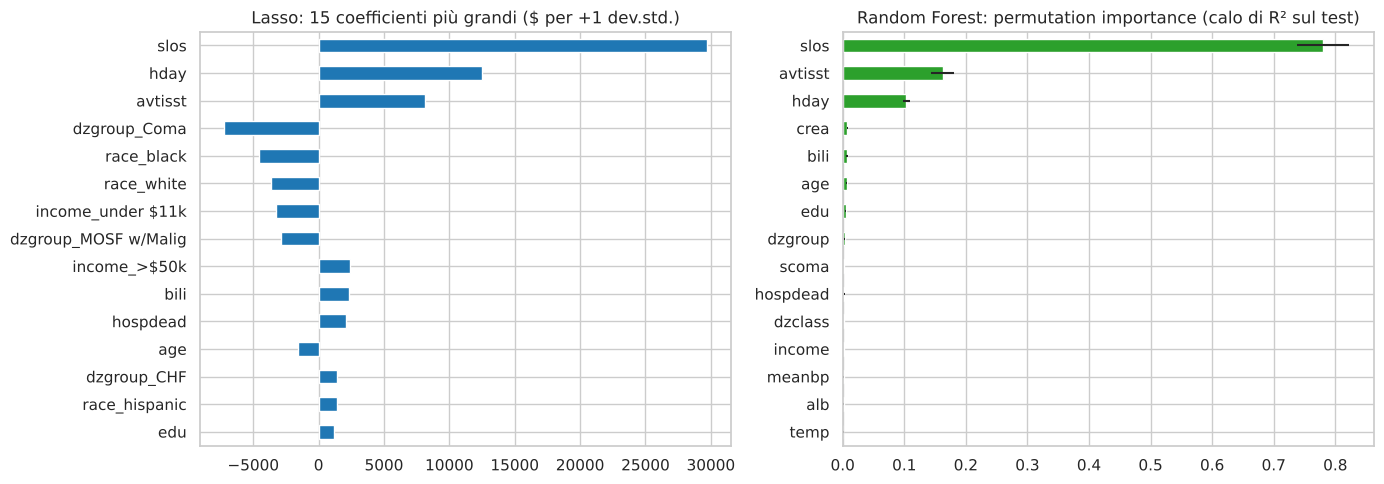

In [20]:
# Lasso: feature con coefficiente diverso da zero
lasso_pipe = tuned["Lasso (tuned)"]
lasso_coef = pd.Series(lasso_pipe.named_steps["model"].coef_, index=feat_names)
lasso_nz = lasso_coef[lasso_coef != 0].sort_values(key=abs, ascending=False)
print(f"alpha scelto = {lasso_pipe.named_steps['model'].alpha:.4g}; feature con coefficiente ≠ 0: {len(lasso_nz)} su {len(lasso_coef)}")
display(lasso_nz.head(15).round(0).to_frame("coefficiente ($ per +1 dev.std.)"))

# Permutation importance della Random Forest (sulle colonne originali, sul test set)
rf_pipe = tuned["Random Forest (tuned)"]
pi = permutation_importance(rf_pipe, Xte_B, y_te, n_repeats=5, random_state=RANDOM_STATE, scoring="r2")
pi_df = pd.DataFrame({"importanza": pi.importances_mean, "std": pi.importances_std}, index=Xte_B.columns)
pi_df = pi_df.sort_values("importanza", ascending=False)
display(pi_df.head(12).round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
lasso_nz.head(15).iloc[::-1].plot.barh(ax=axes[0], color="tab:blue")
axes[0].set_title("Lasso: 15 coefficienti più grandi ($ per +1 dev.std.)")
pi_df.head(15).iloc[::-1]["importanza"].plot.barh(ax=axes[1], xerr=pi_df.head(15).iloc[::-1]["std"], color="tab:green")
axes[1].set_title("Random Forest: permutation importance (calo di R² sul test)")
plt.tight_layout()
plt.show()

**Commento.**

- **Forward selection.** Bastano **3 feature** (`slos`, `hday`, `avtisst`): il R² in cross-validation è 0.742, contro 0.757 con tutte le 53 colonne. Dopo la quarta feature l'R² cresce in totale di appena 0.011.
- **Lasso.** Con l'`alpha` ottimale tiene 42 feature su 53: poiché la regolarizzazione non serve a migliorare la previsione, `alpha` è piccolo e il Lasso non è selettivo. Anche così, i coefficienti più grandi sono quelli di `slos`, `hday` e `avtisst`.
- **Permutation importance.** Per la Random Forest `slos` pesa molto più di tutte le altre (il R² cala di 0.78 se la si rimescola), poi `avtisst` (0.16) e `hday` (0.10); tutte le altre variabili restano sotto 0.01.

I tre metodi concordano. Il costo di un ricovero cresce soprattutto con la **durata** (`slos` e `hday`, che plausibilmente rappresenta i giorni già trascorsi in ospedale prima dell'ingresso nello studio: insieme danno la durata totale) e con l'**intensità delle cure** (`avtisst`). Le caratteristiche cliniche del paziente (diagnosi, esami, comorbidità) contano molto meno una volta note durata e trattamento. I coefficienti di razza e reddito che compaiono nel Lasso sono piccoli e vanno letti con cautela (possono riflettere differenze tra ospedali): non sono relazioni causali.

### 4.6 Confronto finale e modello scelto

Confrontiamo i modelli con tutte le feature e quelli con feature selezionate: regressione lineare con le feature della forward selection, Lasso, e una Random Forest addestrata solo sulle 10 variabili originali più importanti secondo la permutation importance.

,CV R2,CV R2 std,CV RMSE,Train R2,Test R2,Test RMSE,Test MAE,N. feature
Model,,,,,,,,
Dummy (media),-0.001,0.000,45154.0,0.000,-0.000,48021.0,28803.0,0
Linear Regression,0.757,0.035,22170.0,0.763,0.744,24270.0,11942.0,53
Ridge (tuned),0.757,0.035,22167.0,0.763,0.744,24289.0,11920.0,53
Lasso (tuned),0.757,0.035,22166.0,0.763,0.743,24319.0,11906.0,42
Random Forest (tuned),0.767,0.015,21786.0,0.924,0.785,22249.0,9634.0,53
Gradient Boosting (tuned),0.765,0.027,21849.0,0.830,0.766,23223.0,10761.0,53
"Linear Regression (forward, 3 feat.)",0.742,0.040,22794.0,0.746,0.722,25303.0,12027.0,3
Random Forest (top-10 variabili),0.769,0.014,21667.0,0.908,0.787,22183.0,9776.0,17


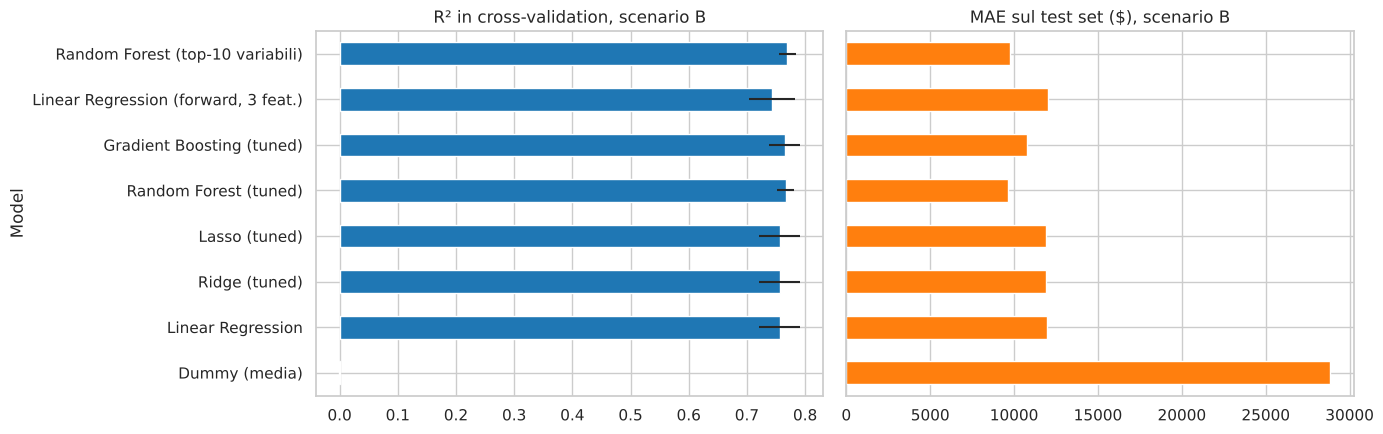

Modello predittivo migliore (R² in cross-validation tra i modelli ottimizzati): Random Forest (tuned)


In [21]:
top10_orig = pi_df.head(10).index.tolist()
subset_rows = [
    evaluate_reg(f"Linear Regression (forward, {k_best} feat.)",
                 Pipeline([("model", LinearRegression())]), Xtr_p[fs_final], y_tr, Xte_p[fs_final], y_te),
    evaluate_reg("Random Forest (top-10 variabili)",
                 make_pipe(Xtr_B[top10_orig], clone(searches["Random Forest"].best_estimator_.named_steps["model"])),
                 Xtr_B[top10_orig], y_tr, Xte_B[top10_orig], y_te),
]
subset_B = pd.DataFrame(subset_rows).set_index("Model")

final_reg = pd.concat([res_B.loc[["Dummy (media)", "Linear Regression"]], tuned_B, subset_B])
n_top10 = len([f for f in feat_names if any(f == c or f.startswith(c + "_") for c in top10_orig)])
final_reg["N. feature"] = [0, Xtr_p.shape[1], Xtr_p.shape[1], len(lasso_nz), Xtr_p.shape[1], Xtr_p.shape[1], k_best, n_top10]
display(show_reg(final_reg))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
final_reg["CV R2"].plot.barh(ax=axes[0], xerr=final_reg["CV R2 std"], color="tab:blue")
axes[0].set_title("R² in cross-validation, scenario B")
final_reg["Test MAE"].plot.barh(ax=axes[1], color="tab:orange")
axes[1].set_title("MAE sul test set ($), scenario B")
plt.tight_layout()
plt.show()

best_name = tuned_B["CV R2"].idxmax()
print("Modello predittivo migliore (R² in cross-validation tra i modelli ottimizzati):", best_name)

**Commento e scelta del modello.**

- **Per la previsione** scegliamo la **Random Forest ottimizzata**: ha il miglior R² in cross-validation tra i modelli ottimizzati (0.767), è la più stabile tra i fold (deviazione standard 0.015) e ha il miglior errore sul test (R² 0.785, MAE ≈ 9600 \$ contro ≈ 11900 \$ della regressione lineare). Il guadagno sul modello lineare è però modesto.
- **Per la spiegazione** il modello più utile è la **regressione lineare a 3 feature**: perde solo circa 0.02 di R² (0.722 sul test contro 0.744 con tutte le feature) usando 3 variabili invece di 53, ed è completamente interpretabile.
- Ridurre la Random Forest alle 10 variabili più importanti non cambia le prestazioni (R² in cross-validation 0.769, sul test 0.787): le altre variabili sono sostanzialmente ridondanti.

### 4.7 Diagnostica del modello scelto e del modello lineare interpretabile

Per il modello migliore guardiamo previsti contro reali e i residui sul test set. Poi, per il modello lineare con feature selezionate, la tabella statistica classica (coefficienti, errori standard, test *t*, p-value). Le feature sono standardizzate, quindi un coefficiente indica di quanti dollari cambia il costo previsto aumentando la feature di una deviazione standard.

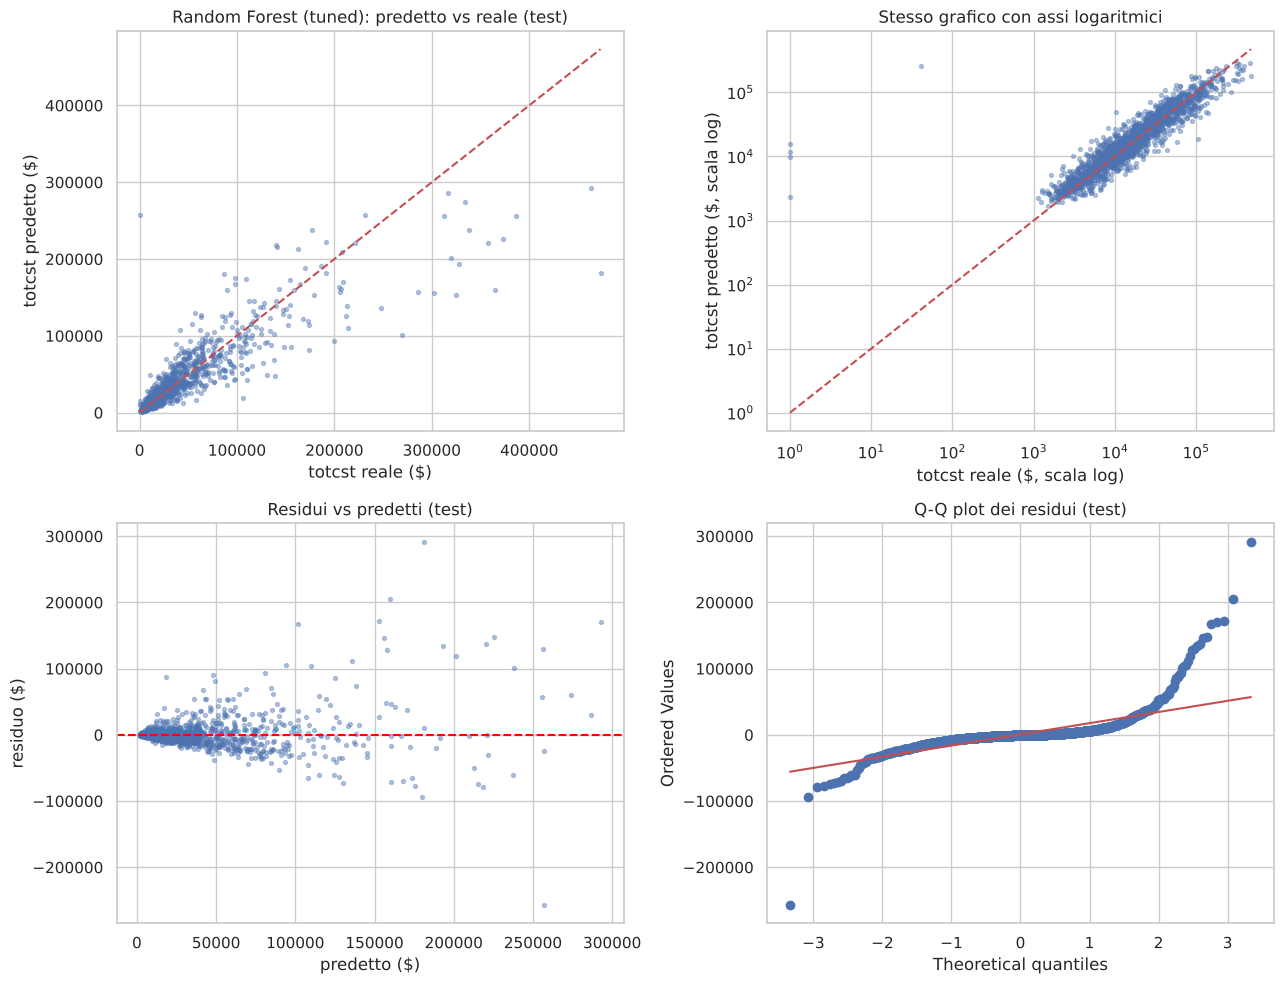

Residui ($): media = 738, dev.std = 22,244, MAE = 9,634


In [22]:
best_pipe = tuned[best_name]
pred_te = best_pipe.predict(Xte_B)
resid = y_te - pred_te

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes[0, 0].scatter(y_te, pred_te, s=8, alpha=0.4)
axes[0, 0].plot([0, y_te.max()], [0, y_te.max()], "r--")
axes[0, 0].set_xlabel("totcst reale ($)")
axes[0, 0].set_ylabel("totcst predetto ($)")
axes[0, 0].set_title(f"{best_name}: predetto vs reale (test)")
axes[0, 1].scatter(y_te + 1, np.clip(pred_te, 1, None), s=8, alpha=0.4)
axes[0, 1].plot([1, y_te.max()], [1, y_te.max()], "r--")
axes[0, 1].set_xscale("log"); axes[0, 1].set_yscale("log")
axes[0, 1].set_xlabel("totcst reale ($, scala log)")
axes[0, 1].set_ylabel("totcst predetto ($, scala log)")
axes[0, 1].set_title("Stesso grafico con assi logaritmici")
axes[1, 0].scatter(pred_te, resid, s=8, alpha=0.4)
axes[1, 0].axhline(0, color="red", ls="--")
axes[1, 0].set_xlabel("predetto ($)")
axes[1, 0].set_ylabel("residuo ($)")
axes[1, 0].set_title("Residui vs predetti (test)")
stats.probplot(resid, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q plot dei residui (test)")
plt.tight_layout()
plt.show()
print(f"Residui ($): media = {resid.mean():,.0f}, dev.std = {resid.std():,.0f}, MAE = {resid.abs().mean():,.0f}")

In [23]:
def ols_summary(X, y):
    """Regressione lineare con errori standard, t-test, p-value, R², R² corretto e test F."""
    Xd = np.column_stack([np.ones(len(X)), X.values])
    beta = np.linalg.lstsq(Xd, y.values, rcond=None)[0]
    res = y.values - Xd @ beta
    n, p = Xd.shape
    dof = n - p
    sigma2 = res @ res / dof
    se = np.sqrt(np.diag(sigma2 * np.linalg.inv(Xd.T @ Xd)))
    tval = beta / se
    pval = 2 * stats.t.sf(np.abs(tval), dof)
    r2 = 1 - (res @ res) / ((y.values - y.values.mean()) ** 2).sum()
    r2_adj = 1 - (1 - r2) * (n - 1) / dof
    F = (r2 / (p - 1)) / ((1 - r2) / dof)
    table = pd.DataFrame({"coef ($)": beta, "errore std": se, "t": tval, "p-value": pval},
                         index=["intercetta"] + list(X.columns))
    return table, {"R2": r2, "R2 corretto": r2_adj, "F": F, "p(F)": stats.f.sf(F, p - 1, dof),
                   "errore std residuo ($)": np.sqrt(sigma2), "gradi di libertà": dof}


ols_table, ols_fit = ols_summary(Xtr_p[fs_final], y_tr)
display(ols_table.round(4))
print({k: (round(float(v), 4)) for k, v in ols_fit.items()})
common = [c for c in fs_final if c in Xtr_B.columns]
print("\nEffetto per unità originale (coef / dev.std. della variabile):")
display((ols_table.loc[common, "coef ($)"] / Xtr_B[common].std()).round(1).to_frame("$ per +1 unità").join(Xtr_B[common].std().round(2).to_frame("dev.std. originale")))

,coef ($),errore std,t,p-value
intercetta,30638.6942,281.0808,109.0032,0.0
slos,29416.3956,297.1320,99.0011,0.0
hday,13082.8898,296.1420,44.1778,0.0
avtisst,9487.1941,303.5728,31.2518,0.0


{'R2': 0.746, 'R2 corretto': 0.7459, 'F': 6430.1224, 'p(F)': 0.0, 'errore std residuo ($)': 22788.3561, 'gradi di libertà': 6569.0}

Effetto per unità originale (coef / dev.std. della variabile):


,$ per +1 unità,dev.std. originale
slos,1428.0,20.60
hday,1382.3,9.46
avtisst,720.5,13.17


**Commento alla diagnostica.**

- La Random Forest segue bene la diagonale per i costi medio-bassi, che sono la grande maggioranza dei ricoveri, ma **sottostima i ricoveri più costosi** (punti sotto la diagonale oltre i 200 mila \$): sono pochissimi casi e difficili da imparare.
- I residui hanno varianza crescente con il costo previsto e code molto pesanti (Q-Q plot): l'errore tipico è piccolo (MAE ≈ 9600 \$), ma pochi pazienti hanno errori da 100-300 mila \$. Il grafico con assi logaritmici mette in evidenza i pochi pazienti con costo reale pari a 0 (a sinistra), che nessun modello può prevedere.
- Nel **modello lineare a 3 feature** tutti i coefficienti sono altamente significativi (p < 0.001; con 6573 pazienti anche effetti piccoli lo sono). A parità delle altre variabili, +1 deviazione standard di `slos` aumenta il costo previsto di circa 29 mila \$, di `hday` di circa 13 mila \$, di `avtisst` di circa 9 mila \$ (l'intercetta, 30.6 mila \$, è il costo medio). In unità originali: circa 1400 \$ per ogni giorno in più di `slos` (deviazione standard 20.6 giorni), circa 1400 \$ per ogni giorno di `hday` e circa 720 \$ per ogni punto di `avtisst`. R² = 0.746, in linea con la cross-validation. Come già osservato, errori non omoschedastici e non normali rendono i p-value solo indicativi.

**Limiti.** (1) I costi quasi nulli sono probabilmente dati mancanti codificati come zero. (2) I ricoveri molto costosi sono pochi, quindi l'errore su di essi resta alto qualunque sia il modello. (3) Le relazioni sono associative, non causali. (4) Escludere `charges` e `totmcst` è una scelta di dominio: se l'obiettivo fosse stimare il costo a partire dalla fattura, il riferimento sarebbe lo scenario A (R² sul test fino a 0.93).

## 5. Classificazione: il paziente è morto entro la fine del 1994?

### 5.1 Analisi di dominio: qual è il target e quali variabili sono lecite

**Target.** Secondo la documentazione del dataset, `death` indica la morte *in qualsiasi momento fino al 31/12/1994*: è esattamente la variabile da predire. Le altre due colonne di esito non sono il target giusto: `hospdead` registra solo la morte **in ospedale** (2360 casi su 6201 decessi) e `d.time` è la durata del follow-up.

**Variabili che contengono già l'esito e vanno escluse** (lo abbiamo visto nelle tabelle della sezione 2.6):

- `hospdead`: se vale 1 allora `death` vale sempre 1. È un sottoinsieme del target.
- `sfdm2`: la categoria `"<2 mo. follow-up"` significa "morto prima dei 2 mesi" e corrisponde a `death = 1` in tutti i 3123 casi.
- `d.time`: tempo alla morte (o alla fine dell'osservazione per chi è vivo).

**Due insiemi di predittori.** Perché la classificazione abbia senso come prognosi, i predittori devono essere informazioni note nei primi giorni di ricovero. Definiamo quindi:

- **Insieme baseline** (analisi principale): anagrafica, malattia, comorbidità, fisiologia al 3° giorno, ADL, `hday`. Esclude anche le cinque variabili che riassumono l'intero ricovero (`slos`, `avtisst`, `charges`, `totcst`, `totmcst`): chi muore presto ha per forza degenze brevi e costi bassi, quindi quelle variabili "sanno" già qualcosa dell'esito.
- **Insieme baseline + ricovero**: aggiunge quelle cinque variabili. Lo usiamo solo come analisi di sensibilità, per quantificare quanto cambierebbero i risultati.

**Metriche.** Il 68% dei pazienti è morto: un classificatore che dice sempre "morto" otterrebbe già il 68% di accuracy. Oltre ad accuracy usiamo **balanced accuracy, precision, recall e F1 sulla classe "morto"**, **ROC-AUC** e **PR-AUC** (che non dipendono dalla soglia), e le matrici di confusione.

In [24]:
cls = base.copy()
y_c = cls["death"]

OUTCOMES = ["death", "d.time", "hospdead", "sfdm2"]
IN_STAY = ["slos", "avtisst", "charges", "totcst", "totmcst"]
X_stay = cls.drop(columns=OUTCOMES)        # baseline + variabili del ricovero
X_c = X_stay.drop(columns=IN_STAY)         # insieme baseline (analisi principale)
print(f"Predittori: baseline = {X_c.shape[1]}, baseline + ricovero = {X_stay.shape[1]}")

Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(X_c, y_c, test_size=0.2, stratify=y_c, random_state=RANDOM_STATE)
skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
print(f"Training: {len(Xc_tr)} pazienti ({yc_tr.mean():.1%} morti)   Test: {len(Xc_te)} pazienti ({yc_te.mean():.1%} morti)")
print(f"Accuracy del classificatore banale 'sempre morto': {yc_te.mean():.3f}")

Predittori: baseline = 28, baseline + ricovero = 33
Training: 7284 pazienti (68.1% morti)   Test: 1821 pazienti (68.1% morti)
Accuracy del classificatore banale 'sempre morto': 0.681


### 5.2 Verifica empirica del leakage

Per mostrare che le esclusioni non sono un dettaglio, addestriamo una regressione logistica (stessa pipeline, cross-validation a 5 fold sul training) con l'insieme baseline e poi aggiungendo, una alla volta, le variabili sospette.

In [25]:
def cv_lr(X_full, label):
    X = X_full.loc[Xc_tr.index]
    r = cross_validate(make_pipe(X, LogisticRegression(max_iter=2000)), X, yc_tr, cv=skf,
                       scoring={"auc": "roc_auc", "bal": "balanced_accuracy"})
    return {"Insieme di predittori": label, "ROC-AUC (CV)": r["test_auc"].mean(), "Balanced accuracy (CV)": r["test_bal"].mean()}


leak = pd.DataFrame([
    cv_lr(X_c, "baseline (analisi principale)"),
    cv_lr(X_stay, "baseline + variabili del ricovero (slos, avtisst, costi)"),
    cv_lr(X_c.assign(hospdead=cls["hospdead"]), "baseline + hospdead"),
    cv_lr(X_c.assign(sfdm2=cls["sfdm2"].fillna("missing")), "baseline + sfdm2"),
    cv_lr(X_c.assign(**{"d.time": cls["d.time"]}), "baseline + d.time"),
]).set_index("Insieme di predittori")
display(leak.round(3))

,ROC-AUC (CV),Balanced accuracy (CV)
Insieme di predittori,,
baseline (analisi principale),0.765,0.642
"baseline + variabili del ricovero (slos, avtisst, costi)",0.790,0.678
baseline + hospdead,0.860,0.740
baseline + sfdm2,0.884,0.770
baseline + d.time,0.945,0.840


**Commento.** Con le sole informazioni baseline la regressione logistica ottiene una ROC-AUC di 0.765. Aggiungendo `hospdead` sale a 0.860, con `sfdm2` a 0.884, con `d.time` a 0.945: salti di 0.10-0.18 che non dipendono da una migliore comprensione del paziente, ma dal fatto che queste variabili contengono già l'esito (o ne sono una conseguenza diretta). Un modello che le usasse sembrerebbe molto più accurato, ma non servirebbe a prevedere la morte: per questo le escludiamo. Anche le variabili che riassumono il ricovero (`slos`, `avtisst`, costi) alzano la AUC a 0.790: l'aumento è più piccolo, ma sono informazioni disponibili solo a ricovero concluso.

### 5.3 Confronto di classificatori con ottimizzazione degli iperparametri

Sette modelli: baseline banale, regressione logistica, KNN, albero di decisione, Random Forest, Gradient Boosting e SVM con kernel RBF. Per ciascuno, grid search con cross-validation stratificata a 5 fold **sul solo training**, ottimizzando la ROC-AUC (indipendente dalla soglia e adatta a classi sbilanciate). Il test set viene usato una volta sola, alla fine.

In [26]:
def cls_models():
    return {
        "Dummy (maggioranza)": (DummyClassifier(strategy="most_frequent"), None),
        "Logistic Regression": (LogisticRegression(max_iter=2000), {"model__C": [0.01, 0.1, 1, 10]}),
        "KNN": (KNeighborsClassifier(), {"model__n_neighbors": [15, 31, 61]}),
        "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE),
                          {"model__max_depth": [3, 5, 8], "model__min_samples_leaf": [10, 30, 60]}),
        "Random Forest": (RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE),
                          {"model__max_depth": [None, 8], "model__min_samples_leaf": [3, 10]}),
        "Gradient Boosting": (GradientBoostingClassifier(random_state=RANDOM_STATE),
                              {"model__n_estimators": [100, 200], "model__learning_rate": [0.05, 0.1],
                               "model__max_depth": [2, 3]}),
        "SVM (RBF)": (SVC(kernel="rbf"), {"model__C": [0.5, 2, 8]}),
    }


def get_scores(model, X):
    """Probabilità della classe 'morto' (o distanza dall'iperpiano per l'SVM)."""
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)


cls_fitted, cv_info = {}, {}
for name, (est, grid) in cls_models().items():
    pipe = make_pipe(Xc_tr, est)
    if grid:
        gs = GridSearchCV(pipe, grid, cv=skf, scoring="roc_auc", n_jobs=1 if "Forest" in name else -1)
        gs.fit(Xc_tr, yc_tr)
        cls_fitted[name] = gs.best_estimator_
        cv_info[name] = {"CV AUC": gs.best_score_, "CV AUC std": gs.cv_results_["std_test_score"][gs.best_index_],
                         "Parametri": {k.replace("model__", ""): v for k, v in gs.best_params_.items()}}
    else:
        sc = cross_val_score(pipe, Xc_tr, yc_tr, cv=skf, scoring="roc_auc")
        cls_fitted[name] = pipe.fit(Xc_tr, yc_tr)
        cv_info[name] = {"CV AUC": sc.mean(), "CV AUC std": sc.std(), "Parametri": {}}
    print(f"{name:20s} CV AUC = {cv_info[name]['CV AUC']:.4f} ± {cv_info[name]['CV AUC std']:.4f}   {cv_info[name]['Parametri']}", flush=True)

Dummy (maggioranza)  CV AUC = 0.5000 ± 0.0000   {}
Logistic Regression  CV AUC = 0.7652 ± 0.0078   {'C': 1}
KNN                  CV AUC = 0.7381 ± 0.0088   {'n_neighbors': 61}
Decision Tree        CV AUC = 0.7407 ± 0.0065   {'max_depth': 5, 'min_samples_leaf': 30}
Random Forest        CV AUC = 0.7708 ± 0.0114   {'max_depth': None, 'min_samples_leaf': 10}
Gradient Boosting    CV AUC = 0.7724 ± 0.0085   {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}
SVM (RBF)            CV AUC = 0.7573 ± 0.0121   {'C': 0.5}


,CV AUC (train),Accuracy,Balanced acc.,Precision,Recall,F1,ROC-AUC,PR-AUC
Gradient Boosting,0.772,0.742,0.656,0.767,0.893,0.825,0.779,0.877
Random Forest,0.771,0.740,0.640,0.754,0.918,0.828,0.772,0.871
Logistic Regression,0.765,0.737,0.649,0.762,0.892,0.822,0.776,0.873
SVM (RBF),0.757,0.734,0.616,0.739,0.940,0.828,0.763,0.860
Decision Tree,0.741,0.703,0.614,0.744,0.860,0.798,0.721,0.832
KNN,0.738,0.714,0.592,0.727,0.928,0.815,0.738,0.845
Dummy (maggioranza),0.500,0.681,0.500,0.681,1.000,0.810,0.500,0.681


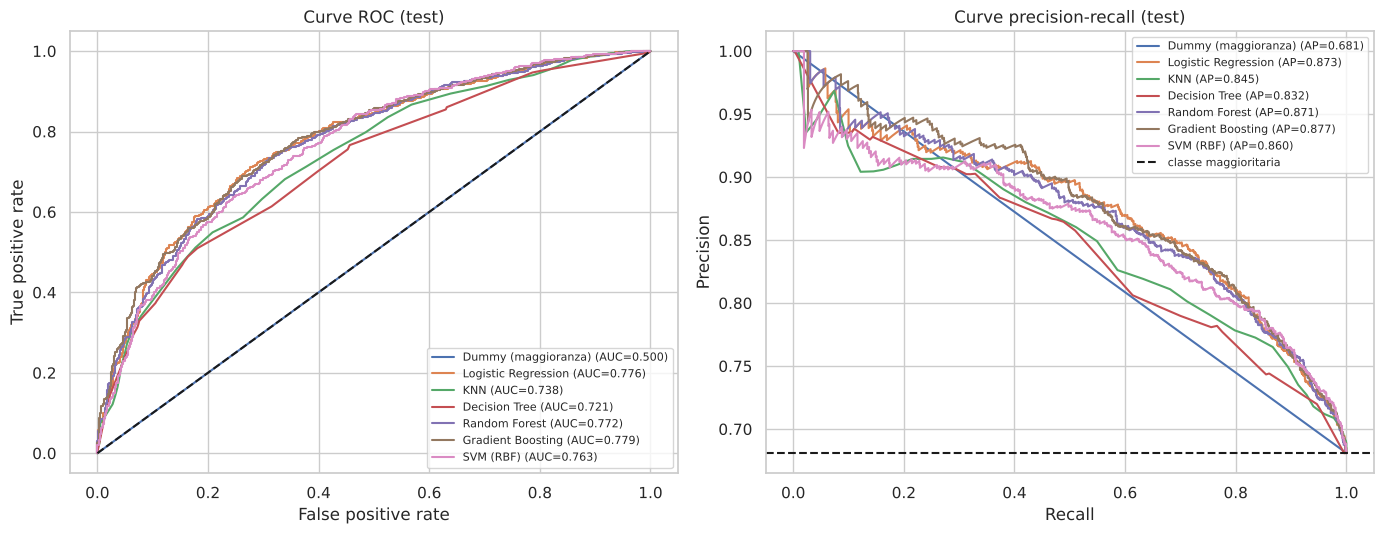

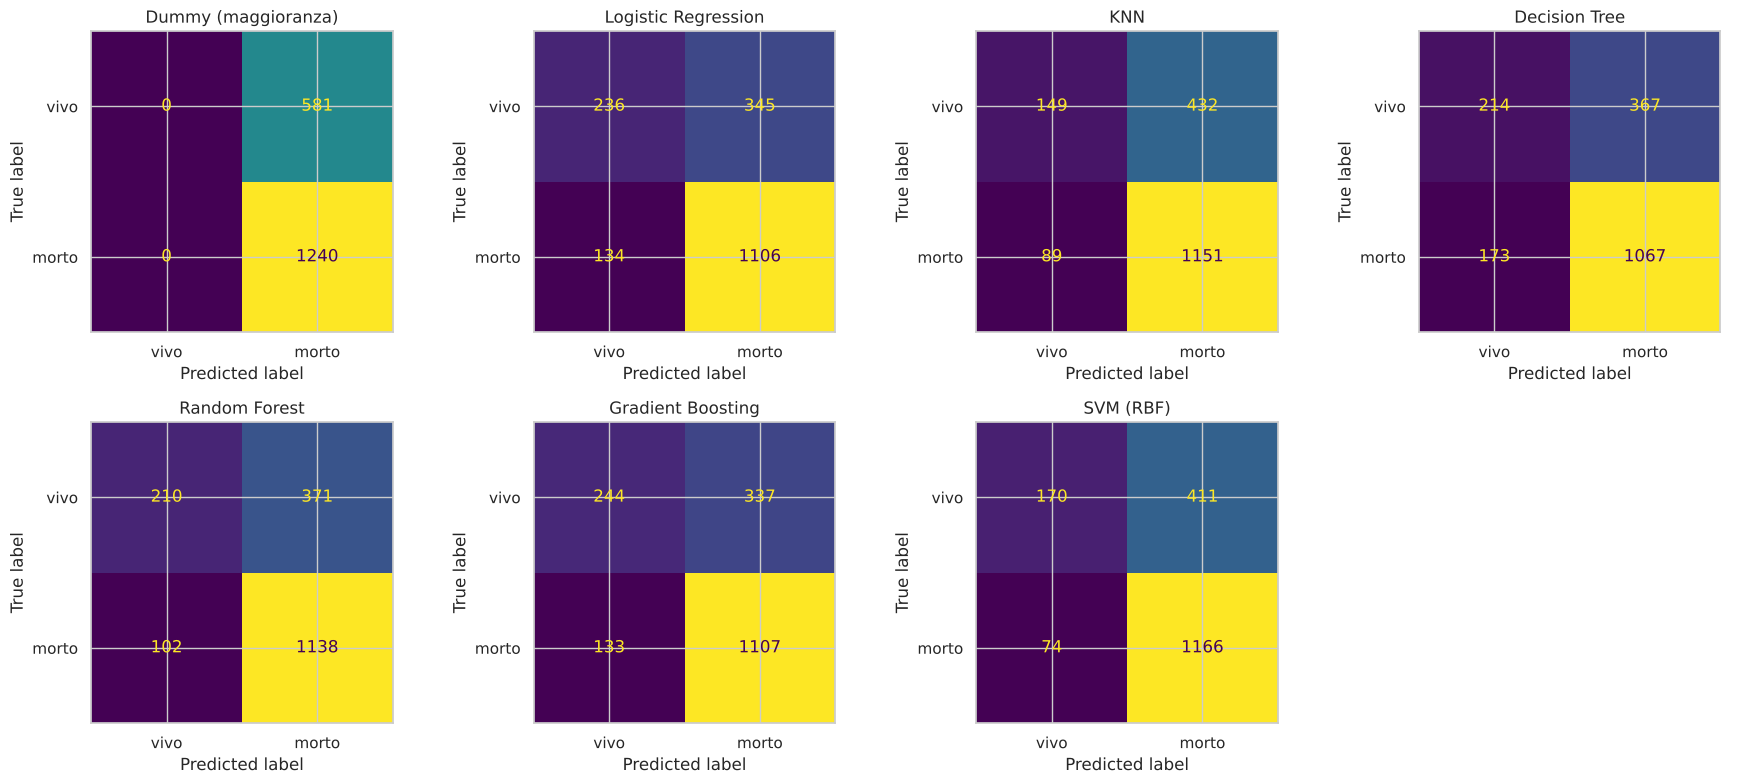

In [27]:
def cls_metrics(y_true, scores, thr):
    pred = (scores >= thr).astype(int)
    return {"Accuracy": accuracy_score(y_true, pred), "Balanced acc.": balanced_accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred, zero_division=0), "Recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred), "ROC-AUC": roc_auc_score(y_true, scores),
            "PR-AUC": average_precision_score(y_true, scores)}


default_thr = lambda model: 0.5 if hasattr(model, "predict_proba") else 0.0
test_scores = {n: get_scores(m, Xc_te) for n, m in cls_fitted.items()}
cls_table = pd.DataFrame({n: cls_metrics(yc_te, test_scores[n], default_thr(cls_fitted[n])) for n in cls_fitted}).T
cls_table.insert(0, "CV AUC (train)", [cv_info[n]["CV AUC"] for n in cls_table.index])
display(cls_table.sort_values("CV AUC (train)", ascending=False).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for n, s in test_scores.items():
    fpr, tpr, _ = roc_curve(yc_te, s)
    axes[0].plot(fpr, tpr, label=f"{n} (AUC={roc_auc_score(yc_te, s):.3f})")
    prec, rec, _ = precision_recall_curve(yc_te, s)
    axes[1].plot(rec, prec, label=f"{n} (AP={average_precision_score(yc_te, s):.3f})")
axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].set_title("Curve ROC (test)")
axes[1].axhline(yc_te.mean(), color="k", ls="--", label="classe maggioritaria")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Curve precision-recall (test)")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (n, m) in zip(axes.ravel(), cls_fitted.items()):
    pred = (test_scores[n] >= default_thr(m)).astype(int)
    ConfusionMatrixDisplay.from_predictions(yc_te, pred, ax=ax, colorbar=False, display_labels=["vivo", "morto"])
    ax.set_title(n)
for ax in axes.ravel()[len(cls_fitted):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Commento.**

- **Baseline.** Il classificatore banale "sempre morto" ha accuracy 0.681, recall 1 e F1 0.810 sulla classe "morto", ma ROC-AUC e balanced accuracy pari a 0.5. **Accuracy e F1 della sola classe maggioritaria ingannano**: un modello quasi inutile le ottiene alte. Per questo il confronto è guidato da ROC-AUC e balanced accuracy.
- **Confronto.** I migliori sono Gradient Boosting (ROC-AUC sul test 0.779), regressione logistica (0.776) e Random Forest (0.772). Le differenze sono più piccole della variabilità tra fold in cross-validation (deviazione standard 0.008-0.011), quindi i tre modelli sono sostanzialmente indistinguibili. SVM (0.763) è un po' peggiore, KNN (0.738) e albero singolo (0.721) sono i peggiori. I risultati sul test sono coerenti con quelli in cross-validation (0.772 per il Gradient Boosting): non c'è overfitting della scelta degli iperparametri.
- **Livello di prestazione.** Con le sole informazioni dei primi giorni il problema è difficile: ROC-AUC ≈ 0.78 e balanced accuracy ≈ 0.66 con soglia 0.5. A quella soglia i modelli dicono "morto" quasi sempre (recall 0.86-0.94) e riconoscono solo una minoranza dei sopravvissuti (per il Gradient Boosting il 42%). Le curve precision-recall stanno sopra la linea della classe maggioritaria (0.68) per tutti i valori di recall.
- Una regressione logistica, interpretabile, vale quanto i modelli più complessi.

### 5.4 Modello migliore: soglia di decisione, importanza delle variabili, analisi di sensibilità

Il modello migliore si sceglie sulla **cross-validation del training** (non sul test). Poiché il default (soglia 0.5) non è necessariamente il compromesso migliore con classi sbilanciate, scegliamo una soglia alternativa **sulle predizioni out-of-fold del training** massimizzando l'indice di Youden (recall + specificità − 1) e la valutiamo poi sul test set. Infine la permutation importance e l'analisi di sensibilità con le variabili del ricovero.

Modello migliore per ROC-AUC in cross-validation: Gradient Boosting {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}
Soglia di Youden (scelta sul training): 0.708  (default: 0.5)


,Accuracy,Balanced acc.,Precision,Recall,F1,ROC-AUC,PR-AUC
soglia di default (0.5),0.742,0.656,0.767,0.893,0.825,0.779,0.877
soglia di Youden (0.71),0.678,0.705,0.859,0.631,0.728,0.779,0.877


Classification report sul test set, soglia di Youden:
              precision    recall  f1-score   support

        vivo      0.497     0.778     0.607       581
       morto      0.859     0.631     0.728      1240

    accuracy                          0.678      1821
   macro avg      0.678     0.705     0.667      1821
weighted avg      0.743     0.678     0.689      1821



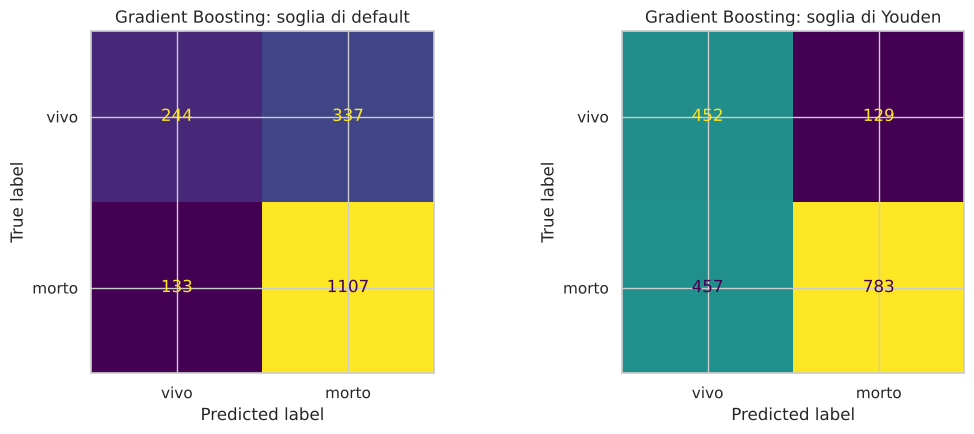

In [28]:
best_cls = max(cv_info, key=lambda n: cv_info[n]["CV AUC"])
best_model = cls_fitted[best_cls]
print("Modello migliore per ROC-AUC in cross-validation:", best_cls, cv_info[best_cls]["Parametri"])

# soglia scelta sulle predizioni out-of-fold del training
method = "predict_proba" if hasattr(best_model, "predict_proba") else "decision_function"
oof = cross_val_predict(clone(best_model), Xc_tr, yc_tr, cv=skf, method=method)
oof = oof[:, 1] if oof.ndim == 2 else oof
fpr, tpr, thr = roc_curve(yc_tr, oof)
thr_youden = float(thr[np.argmax(tpr - fpr)])
print(f"Soglia di Youden (scelta sul training): {thr_youden:.3f}  (default: {default_thr(best_model)})")

s_te = test_scores[best_cls]
cmp_thr = pd.DataFrame({f"soglia di default ({default_thr(best_model)})": cls_metrics(yc_te, s_te, default_thr(best_model)),
                        f"soglia di Youden ({thr_youden:.2f})": cls_metrics(yc_te, s_te, thr_youden)}).T
display(cmp_thr.round(3))

print("Classification report sul test set, soglia di Youden:")
print(classification_report(yc_te, (s_te >= thr_youden).astype(int), target_names=["vivo", "morto"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, t_, title in zip(axes, [default_thr(best_model), thr_youden], ["soglia di default", "soglia di Youden"]):
    ConfusionMatrixDisplay.from_predictions(yc_te, (s_te >= t_).astype(int), ax=ax, colorbar=False,
                                            display_labels=["vivo", "morto"])
    ax.set_title(f"{best_cls}: {title}")
plt.tight_layout()
plt.show()

,importanza,std
ca,0.1008,0.0107
age,0.0421,0.0048
scoma,0.0375,0.0045
adlsc,0.0196,0.0035
bun,0.0195,0.0051
dzgroup,0.0137,0.0039
hday,0.0101,0.0022
num.co,0.0076,0.0022
crea,0.0062,0.0023
sex,0.0014,0.0008


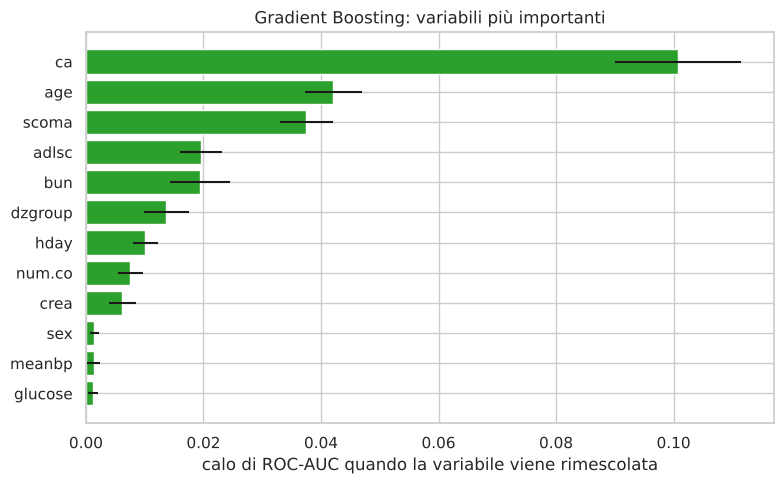

,Accuracy,Balanced acc.,Precision,Recall,F1,ROC-AUC,PR-AUC
baseline,0.742,0.656,0.767,0.893,0.825,0.779,0.877
baseline + ricovero,0.762,0.696,0.794,0.879,0.834,0.822,0.910


In [29]:
# Permutation importance (sulle variabili originali, sul test set, scoring ROC-AUC)
pi_c = permutation_importance(best_model, Xc_te, yc_te, n_repeats=10, random_state=RANDOM_STATE, scoring="roc_auc")
pi_c = pd.DataFrame({"importanza": pi_c.importances_mean, "std": pi_c.importances_std}, index=Xc_te.columns)
pi_c = pi_c.sort_values("importanza", ascending=False)
display(pi_c.head(12).round(4))
top = pi_c.head(12).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top.index, top["importanza"], xerr=top["std"], color="tab:green")
plt.xlabel("calo di ROC-AUC quando la variabile viene rimescolata")
plt.title(f"{best_cls}: variabili più importanti")
plt.tight_layout()
plt.show()

# Analisi di sensibilità: stesso tipo di modello e iperparametri, ma con le variabili del ricovero
Xs_tr, Xs_te = X_stay.loc[Xc_tr.index], X_stay.loc[Xc_te.index]
m_stay = make_pipe(Xs_tr, clone(best_model.named_steps["model"])).fit(Xs_tr, yc_tr)
s_stay = get_scores(m_stay, Xs_te)
sens = pd.DataFrame({"baseline": cls_metrics(yc_te, s_te, default_thr(best_model)),
                     "baseline + ricovero": cls_metrics(yc_te, s_stay, default_thr(m_stay))}).T
display(sens.round(3))

**Commento.**

- **Soglia.** Con la soglia di default il Gradient Boosting riconosce l'89% dei decessi ma solo il 42% dei sopravvissuti (balanced accuracy 0.656). Con la soglia di Youden (0.71, scelta sul training) la balanced accuracy sale a 0.705: si riconosce il 78% dei sopravvissuti e il 63% dei decessi, e la precisione sulla classe "morto" passa da 0.77 a 0.86. L'accuracy invece scende (da 0.742 a 0.678, persino sotto lo 0.681 del classificatore banale): un esempio di come l'accuracy non misuri ciò che interessa. Quale soglia sia preferibile dipende dal costo relativo degli errori (ad esempio non pianificare cure palliative per chi morirà, oppure pianificarle per chi sopravvivrà) e andrebbe deciso con i clinici; la ROC-AUC (0.779) non dipende dalla soglia.
- **Variabili importanti.** Per il Gradient Boosting contano soprattutto `ca` (tumore e metastasi: il calo di AUC se la si rimescola è 0.10), poi età (0.042), punteggio di coma (0.038), autonomia nelle attività quotidiane (`adlsc`), azotemia (`bun`), gruppo diagnostico, `hday`, comorbidità e creatinina. Tutte le altre pesano meno di 0.002. Sono variabili cliniche coerenti con il dominio e sono le informazioni che userebbe un medico per la prognosi.
- **Analisi di sensibilità.** Aggiungendo le variabili che riassumono il ricovero, la ROC-AUC sul test passa da 0.779 a 0.822 e la balanced accuracy da 0.656 a 0.696. Il miglioramento (+0.04) è moderato ma, come discusso, quelle variabili sono note solo a ricovero concluso e in parte "sanno" già chi è morto presto (degenze brevi, costi bassi).

**Limiti.** (1) `death` copre un orizzonte lungo e variabile (fino a circa 5 anni e mezzo): mescola decessi precoci e tardivi, e un modello di sopravvivenza (*time-to-event*) userebbe `d.time` nel modo corretto. (2) Molti valori sono mancanti (glucosio, diuresi, albumina) e il valore "normale" di riempimento li fa apparire sani, mentre l'assenza della misura può essere essa stessa informativa. (3) Non abbiamo calibrato le probabilità.

## 6. Clustering: si riconoscono diversi gradi di gravità?

### 6.1 Impostazione

`sfdm2` misura la disabilità funzionale a 2 mesi ed è una variabile **ordinale** (secondo la documentazione i livelli, in ordine crescente di gravità, sono: 1 nessun segno di disabilità, 2 ≥4 ADL compromesse, 3 Sickness Impact Profile ≥ 30, 4 intubato o in coma, 5 morto prima dei 2 mesi).

**Come leggiamo la richiesta.** Il clustering è non supervisionato, quindi **non usa `sfdm2` per costruire i cluster**: lo usiamo come *riferimento esterno* per capire se i gruppi che gli algoritmi trovano a partire dalle condizioni cliniche del paziente corrispondono a gradi di gravità diversi. Se i cluster fossero allineati a `sfdm2`, allora la gravità sarebbe "visibile" nei dati clinici.

**Pazienti.** Servono i pazienti con `sfdm2` osservato (7705 su 9105): chi non lo ha non può essere valutato rispetto al riferimento.

**Variabili usate per il clustering**: 19 variabili cliniche numeriche, cioè età, comorbidità, coma, intensità del trattamento (`avtisst`), ADL, parametri vitali e esami del 3° giorno. Sono escluse `sps`/`aps` (vietate dalla consegna), i costi (misurano l'uso di risorse e non la condizione clinica), gli esiti (`death`, `hospdead`, `d.time`) e naturalmente `sfdm2`.

**Preprocessing.** Mediana per i pochi mancanti; trasformazione `log(1 + x)` delle variabili molto asimmetriche (skewness > 1) per evitare che pochi valori estremi (es. bilirubina, creatinina) dominino le distanze; standardizzazione. Il clustering è non supervisionato e senza train/test, quindi questi passaggi si fanno sull'intero insieme.

**Metriche.** *Interne* (misurano la qualità dei cluster senza etichette): silhouette (alta = meglio), Calinski-Harabasz (alta = meglio), Davies-Bouldin (bassa = meglio). *Esterne* (confronto con `sfdm2`): Adjusted Rand Index (ARI), Normalized Mutual Information (NMI), omogeneità e completezza.

In [30]:
ORDER = ["no(M2 and SIP pres)", "adl>=4 (>=5 if sur)", "SIP>=30", "Coma or Intub", "<2 mo. follow-up"]
clu = base[base["sfdm2"].notna()].copy()
clu["sfdm2_level"] = clu["sfdm2"].map({lvl: i + 1 for i, lvl in enumerate(ORDER)}).astype(int)
print(f"Pazienti con sfdm2 osservato: {len(clu)} su {len(base)}")
display(clu["sfdm2"].value_counts().reindex(ORDER).to_frame("pazienti").assign(livello=range(1, 6)))

CLU_FEATURES = ["age", "num.co", "scoma", "avtisst", "adlsc", "meanbp", "hrt", "resp", "temp", "wblc",
                "pafi", "alb", "bili", "crea", "sod", "ph", "glucose", "bun", "urine"]
Xraw = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(clu[CLU_FEATURES]),
                    columns=CLU_FEATURES, index=clu.index)
skew = Xraw.skew()
log_feats = skew[(skew > 1) & (Xraw.min() >= 0)].index.tolist()
print("\nVariabili trasformate con log(1+x) (skewness > 1):", log_feats)
Xt = Xraw.copy()
Xt[log_feats] = np.log1p(Xt[log_feats])
Zc = StandardScaler().fit_transform(Xt)
y_ref = clu["sfdm2_level"].values
print("Matrice per il clustering:", Zc.shape)

Pazienti con sfdm2 osservato: 7705 su 9105


,pazienti,livello
sfdm2,,
no(M2 and SIP pres),3061,1
adl>=4 (>=5 if sur),916,2
SIP>=30,564,3
Coma or Intub,41,4
<2 mo. follow-up,3123,5



Variabili trasformate con log(1+x) (skewness > 1): ['scoma', 'wblc', 'alb', 'bili', 'crea', 'glucose', 'bun']
Matrice per il clustering: (7705, 19)


### 6.2 Visualizzazione preliminare (PCA) e scelta del numero di cluster per K-Means

Proiettiamo i pazienti sulle prime due componenti principali, colorandoli per livello di `sfdm2`, per vedere a occhio se i gradi di gravità sono separati. Poi, per K-Means, confrontiamo le metriche interne al variare di *k*.

Varianza spiegata dalle prime due componenti: [0.117 0.093] → 0.21


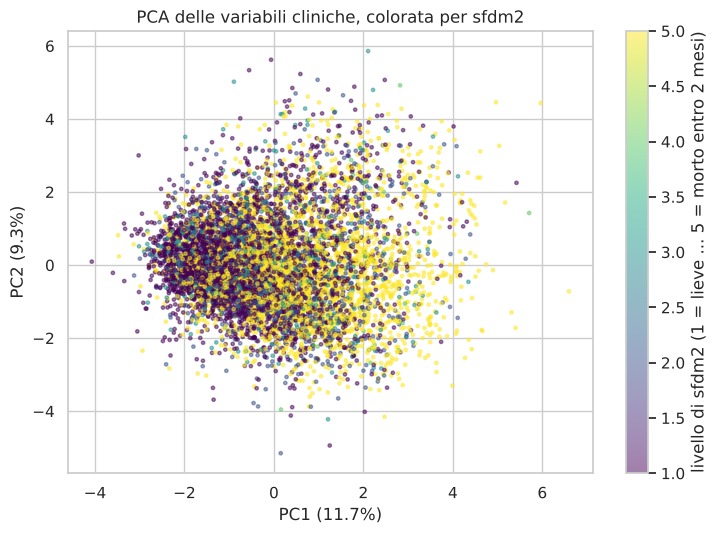

In [31]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(Zc)
P = pca.transform(Zc)
print("Varianza spiegata dalle prime due componenti:", pca.explained_variance_ratio_.round(3), "→", round(pca.explained_variance_ratio_.sum(), 3))

fig, ax = plt.subplots(figsize=(7.5, 5.5))
sc_ = ax.scatter(P[:, 0], P[:, 1], c=y_ref, cmap="viridis", s=6, alpha=0.5)
plt.colorbar(sc_, label="livello di sfdm2 (1 = lieve ... 5 = morto entro 2 mesi)")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.set_title("PCA delle variabili cliniche, colorata per sfdm2")
plt.tight_layout()
plt.show()

,Inertia,Silhouette,Calinski-Harabasz,Davies-Bouldin
k,,,,
2,134779.134,0.110,663.885,3.297
3,127869.298,0.097,557.937,3.015
4,123757.914,0.086,469.541,2.901
5,119772.589,0.080,427.882,2.820
6,116821.958,0.060,389.795,2.804
7,114421.965,0.060,358.510,2.778
8,112224.178,0.059,334.805,2.713
9,110297.329,0.063,314.841,2.645
10,108652.128,0.042,297.004,2.696


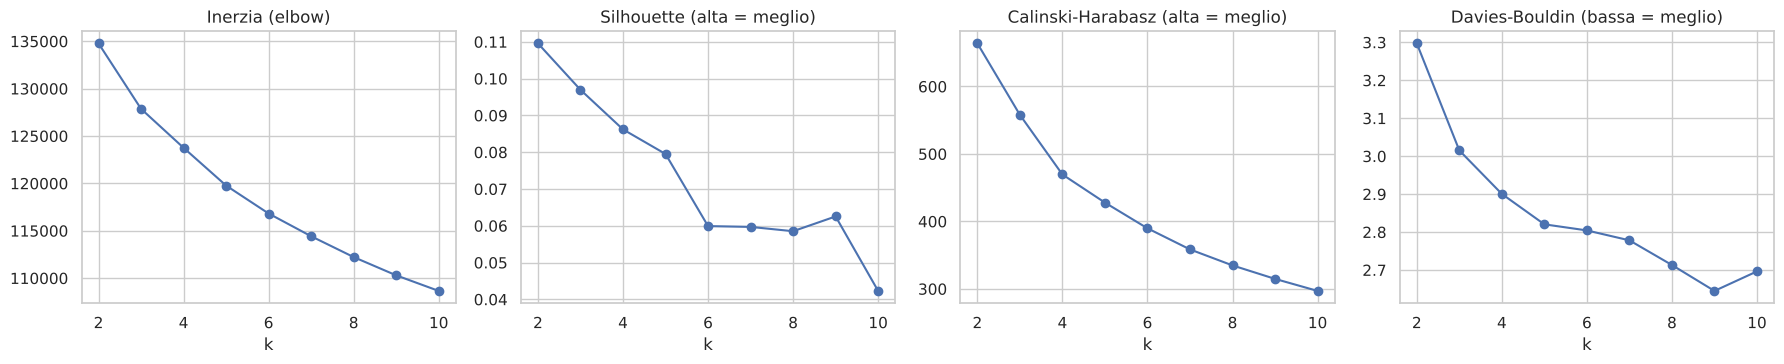

In [32]:
ks = range(2, 11)
km_rows = []
for k in ks:
    km_ = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Zc)
    km_rows.append({"k": k, "Inertia": km_.inertia_, "Silhouette": silhouette_score(Zc, km_.labels_),
                    "Calinski-Harabasz": calinski_harabasz_score(Zc, km_.labels_),
                    "Davies-Bouldin": davies_bouldin_score(Zc, km_.labels_)})
km_sel = pd.DataFrame(km_rows).set_index("k")
display(km_sel.round(3))

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, (col, title) in zip(axes, [("Inertia", "Inerzia (elbow)"), ("Silhouette", "Silhouette (alta = meglio)"),
                                   ("Calinski-Harabasz", "Calinski-Harabasz (alta = meglio)"),
                                   ("Davies-Bouldin", "Davies-Bouldin (bassa = meglio)")]):
    ax.plot(km_sel.index, km_sel[col], "o-")
    ax.set_title(title)
    ax.set_xlabel("k")
plt.tight_layout()
plt.show()

**Commento.** Le metriche interne non indicano alcuna struttura netta. La silhouette è bassa per ogni *k* (massimo 0.110 con *k* = 2, poi in calo) e secondo la regola empirica di Kaufman e Rousseeuw valori sotto 0.25 indicano l'assenza di una struttura di cluster sostanziale. L'inerzia non ha un "gomito" riconoscibile, e Calinski-Harabasz e Davies-Bouldin danno indicazioni opposte (la prima favorisce *k* piccoli, la seconda *k* grandi): nessun valore di *k* è nettamente preferibile. Anche la PCA mostra una nuvola continua: i pazienti di livello 5 (gialli) tendono verso destra e quelli di livello 1 (viola) verso sinistra, ma con una forte sovrapposizione, e le prime due componenti spiegano solo il 21% della varianza.

### 6.3 Confronto tra algoritmi e misure di distanza

Confrontiamo quattro famiglie di algoritmi con **5 cluster** (tanti quanti i livelli di `sfdm2`), così il confronto con il riferimento è alla pari:

- **K-Means** (distanza euclidea);
- **Gaussian Mixture** (covarianza piena e diagonale);
- **Clustering gerarchico agglomerativo**: *ward* (solo euclidea) e *complete*, *average*, *single* linkage, ciascuno con **distanza euclidea, Manhattan e coseno**;
- **DBSCAN** con distanza euclidea e Manhattan; `min_samples = 20` e `eps` scelto come percentile (50°, 80°, 95°) della distanza dal 20° vicino (grafico k-distance). DBSCAN decide da solo il numero di cluster e può etichettare punti come rumore.

Per ogni soluzione riportiamo anche **la quota del cluster più grande** e **la quota di rumore**: una silhouette alta può nascondere una soluzione degenere (un cluster gigante più pochi outlier). Le soluzioni con un cluster che contiene oltre il 60% dei pazienti (soglia convenzionale: una partizione così sbilanciata non separa livelli di gravità) o con meno di 2 cluster sono segnalate come *degeneri* e non vengono considerate nella scelta del migliore; la tabella le riporta comunque tutte. Per DBSCAN le metriche interne sono calcolate sui punti non-rumore; la silhouette usa la stessa distanza dell'algoritmo.

In [33]:
def evaluate_clustering(Z, labels, metric="euclidean"):
    labels = np.asarray(labels)
    counts = pd.Series(labels).value_counts()
    core = labels != -1
    n_cl = len(set(labels[core]))
    out = {"n. cluster": n_cl, "cluster max (%)": 100 * counts.drop(-1, errors="ignore").max() / len(labels) if n_cl else np.nan,
           "rumore (%)": 100 * (~core).mean()}
    if n_cl >= 2:
        out["Silhouette"] = silhouette_score(Z[core], labels[core], metric=metric)
        out["Calinski-Harabasz"] = calinski_harabasz_score(Z[core], labels[core])
        out["Davies-Bouldin"] = davies_bouldin_score(Z[core], labels[core])
    out["ARI"] = adjusted_rand_score(y_ref, labels)
    out["NMI"] = normalized_mutual_info_score(y_ref, labels)
    out["Omogeneità"] = homogeneity_score(y_ref, labels)
    out["Completezza"] = completeness_score(y_ref, labels)
    return out


K = 5
rows, all_labels = [], {}


def add(algo, dist, labels, sil_metric="euclidean"):
    row = {"Algoritmo": algo, "Distanza": dist}
    row.update(evaluate_clustering(Zc, labels, sil_metric))
    rows.append(row)
    all_labels[(algo, dist)] = np.asarray(labels)


add("K-Means", "euclidea", KMeans(K, n_init=10, random_state=RANDOM_STATE).fit_predict(Zc))
for cov in ["full", "diag"]:
    add(f"GMM ({cov})", "-", GaussianMixture(K, covariance_type=cov, n_init=3, random_state=RANDOM_STATE).fit(Zc).predict(Zc))

linkages = {}
for dist, scipy_metric in [("euclidea", "euclidean"), ("Manhattan", "cityblock"), ("coseno", "cosine")]:
    D = pdist(Zc, metric=scipy_metric)
    for method in (["ward"] if dist == "euclidea" else []) + ["complete", "average", "single"]:
        L = linkage(D, method=method)
        linkages[(method, dist)] = L
        add(f"Gerarchico ({method})", dist, fcluster(L, K, criterion="maxclust") - 1, scipy_metric)
    del D

MIN_S = 20
kdists = {}
for dist, sk_metric in [("euclidea", "euclidean"), ("Manhattan", "manhattan")]:
    nn = NearestNeighbors(n_neighbors=MIN_S, metric=sk_metric).fit(Zc)
    kd = np.sort(nn.kneighbors(Zc)[0][:, -1])
    kdists[dist] = kd
    for q in [0.5, 0.8, 0.95]:
        eps = float(np.quantile(kd, q))
        add(f"DBSCAN (eps={eps:.2f}, q{int(q * 100)})", dist, DBSCAN(eps=eps, min_samples=MIN_S, metric=sk_metric).fit_predict(Zc), sk_metric)

clu_res = pd.DataFrame(rows)
clu_res["degenere"] = (clu_res["cluster max (%)"] > 60) | (clu_res["n. cluster"] < 2)
display(clu_res.sort_values("Silhouette", ascending=False).round(3).reset_index(drop=True))

,Algoritmo,Distanza,n. cluster,cluster max (%),rumore (%),Silhouette,Calinski-Harabasz,Davies-Bouldin,ARI,NMI,Omogeneità,Completezza,degenere
0,Gerarchico (single),euclidea,5,99.935,0.000,0.411,7.750,0.510,-0.000,0.001,0.000,0.066,True
1,Gerarchico (average),euclidea,5,99.766,0.000,0.361,17.570,1.044,0.000,0.002,0.001,0.057,True
2,Gerarchico (average),Manhattan,5,99.831,0.000,0.359,11.254,1.041,0.000,0.003,0.002,0.137,True
3,Gerarchico (single),Manhattan,5,99.948,0.000,0.326,6.186,0.402,-0.000,0.001,0.000,0.092,True
4,Gerarchico (complete),Manhattan,5,88.540,0.000,0.160,109.691,2.528,-0.003,0.008,0.006,0.016,True
5,Gerarchico (complete),euclidea,5,79.403,0.000,0.091,89.482,3.186,0.004,0.002,0.001,0.002,True
6,K-Means,euclidea,5,39.390,0.000,0.080,427.882,2.820,0.056,0.055,0.061,0.049,False
7,Gerarchico (ward),euclidea,5,42.661,0.000,0.053,255.848,3.242,0.011,0.013,0.013,0.013,False
8,Gerarchico (average),coseno,5,31.823,0.000,0.051,231.538,3.731,0.039,0.033,0.037,0.031,False
9,GMM (full),-,5,35.496,0.000,0.022,214.588,4.654,0.038,0.049,0.053,0.045,False


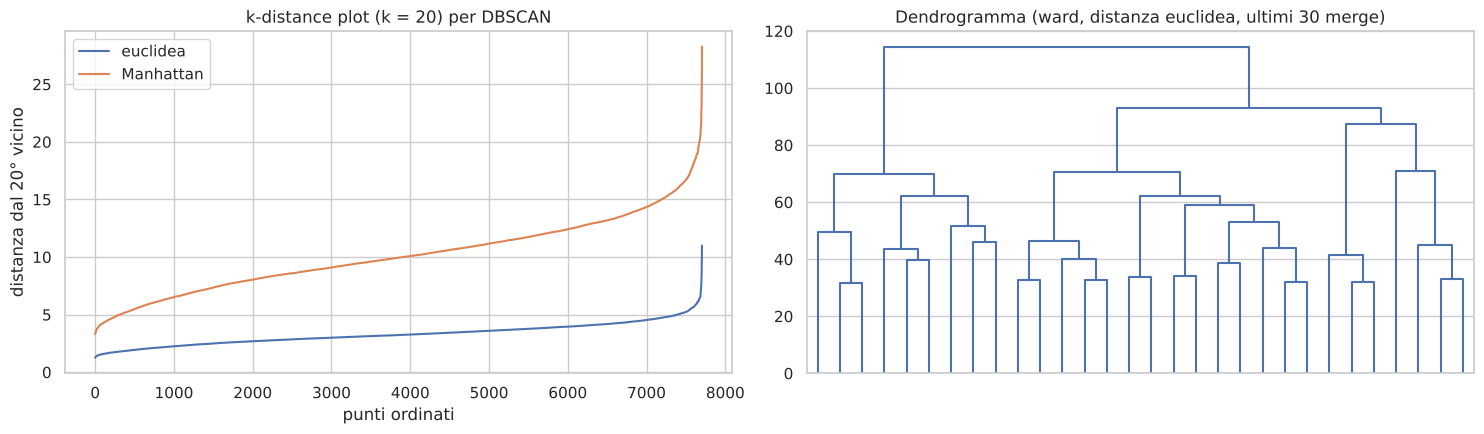

Soluzioni non degeneri: 6 su 19
Migliore per silhouette: K-Means - euclidea (silhouette = 0.080, NMI = 0.055)
Migliore per NMI con sfdm2: K-Means - euclidea (NMI = 0.055, silhouette = 0.080)


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for dist, kd in kdists.items():
    axes[0].plot(kd, label=dist)
axes[0].set_title(f"k-distance plot (k = {MIN_S}) per DBSCAN")
axes[0].set_xlabel("punti ordinati")
axes[0].set_ylabel("distanza dal 20° vicino")
axes[0].legend()

L = linkages[("ward", "euclidea")]
dendrogram(L, truncate_mode="lastp", p=30, no_labels=True, ax=axes[1], color_threshold=0)
axes[1].set_title("Dendrogramma (ward, distanza euclidea, ultimi 30 merge)")
plt.tight_layout()
plt.show()

valid = clu_res[~clu_res["degenere"]]
print("Soluzioni non degeneri:", len(valid), "su", len(clu_res))
b_int = valid["Silhouette"].idxmax()
b_ext = valid["NMI"].idxmax()
print("Migliore per silhouette:", clu_res.loc[b_int, "Algoritmo"], "-", clu_res.loc[b_int, "Distanza"],
      f"(silhouette = {clu_res.loc[b_int, 'Silhouette']:.3f}, NMI = {clu_res.loc[b_int, 'NMI']:.3f})")
print("Migliore per NMI con sfdm2:", clu_res.loc[b_ext, "Algoritmo"], "-", clu_res.loc[b_ext, "Distanza"],
      f"(NMI = {clu_res.loc[b_ext, 'NMI']:.3f}, silhouette = {clu_res.loc[b_ext, 'Silhouette']:.3f})")

**Commento.**

- **Soluzioni degeneri.** Le silhouette più alte (0.33-0.41) appartengono al clustering gerarchico *single* e *average* con distanza euclidea e Manhattan, ma in quelle soluzioni oltre il 99% dei pazienti sta in un solo cluster e gli altri quattro sono pochi outlier. Il punteggio è alto perché quasi tutti i punti sono vicini al cluster gigante, non perché ci siano gruppi ben separati: sono artefatti, e lo confermano Calinski-Harabasz molto bassi (6-18) e NMI praticamente nullo. Lo stesso vale per **DBSCAN**: con tutti i valori di `eps` provati e con entrambe le distanze trova un solo cluster più rumore, perché nei dati non ci sono regioni dense separate da zone vuote (la curva k-distance è continua e senza "gomito" fino agli ultimissimi punti). Anche il dendrogramma di Ward non ha un salto netto nelle altezze di fusione che suggerisca un numero naturale di cluster.
- **Soluzioni utilizzabili.** Tra quelle non degeneri **K-Means è il migliore sia per silhouette (0.080) sia per accordo con `sfdm2` (NMI 0.055, ARI 0.056)**; il GMM con covarianza piena è vicino (NMI 0.049), quello con covarianza diagonale e Ward sono peggiori (NMI 0.026 e 0.013).
- **Effetto della distanza.** Nel gerarchico, con *complete* e *average* le distanze euclidea e Manhattan, sensibili agli outlier, producono un cluster dominante (79-99% dei pazienti). La distanza **coseno**, che confronta la forma del profilo e non la distanza assoluta, dà invece cluster molto più bilanciati (27-32% il più grande) e un NMI più alto (0.025-0.033 contro 0.002-0.008), pur restando sotto K-Means. La silhouette è calcolata con la distanza dell'algoritmo, quindi non è perfettamente confrontabile tra distanze diverse.
- In assoluto la qualità è bassa per tutti: tra le soluzioni non degeneri silhouette ≤ 0.08 e NMI ≤ 0.06.

### 6.4 Quanto è realistico aspettarsi un buon accordo? Un riferimento supervisionato

I cluster sono costruiti solo con le variabili cliniche. Per capire quale accordo con `sfdm2` sia ragionevole aspettarsi, vediamo cosa riesce a fare un modello **supervisionato** (Random Forest, cross-validation a 5 fold) che prova a prevedere il livello di `sfdm2` dalle stesse variabili: il suo NMI è un riferimento superiore per qualunque clustering.

In [35]:
rf_ref = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE)
pred_ref = cross_val_predict(rf_ref, Zc, y_ref, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE))
print(f"Random Forest supervisionata (CV): accuracy = {accuracy_score(y_ref, pred_ref):.3f}, balanced accuracy = {balanced_accuracy_score(y_ref, pred_ref):.3f}")
print(f"   ARI = {adjusted_rand_score(y_ref, pred_ref):.3f}   NMI = {normalized_mutual_info_score(y_ref, pred_ref):.3f}")
print(f"Classificatore banale (sempre il livello più frequente): accuracy = {pd.Series(y_ref).value_counts(normalize=True).max():.3f}")

Random Forest supervisionata (CV): accuracy = 0.633, balanced accuracy = 0.317
   ARI = 0.218   NMI = 0.159
Classificatore banale (sempre il livello più frequente): accuracy = 0.405


**Commento.** Anche un modello **supervisionato**, che conosce le etichette di `sfdm2`, ottiene da queste variabili solo NMI = 0.159 e ARI = 0.218 (balanced accuracy 0.32, mentre il caso su 5 classi darebbe 0.20): i 5 livelli di disabilità non sono prevedibili con precisione dalle misure cliniche del 3° giorno. Un clustering non supervisionato difficilmente può fare molto meglio, e l'NMI di 0.055 del K-Means è circa un terzo di questo riferimento.

### 6.5 Analisi della soluzione scelta

Analizziamo in dettaglio il K-Means (risultato il migliore tra le soluzioni non degeneri, vedi sopra) con il numero di cluster suggerito dalla silhouette e, per confronto, con *k* = 5. Per ogni soluzione:

- **tabella di contingenza** normalizzata per cluster: come si distribuiscono i livelli di `sfdm2` dentro ciascun cluster;
- **profilo clinico** dei cluster (medie standardizzate delle variabili);
- **test statistici**: Kruskal-Wallis (i livelli di `sfdm2` differiscono tra i cluster?) e correlazione di Spearman tra il "rango di gravità" del cluster (clusters ordinati per livello medio di `sfdm2`) e il livello di `sfdm2` del paziente (misura ordinale di accordo).

k suggerito dalla silhouette per K-Means: 2


,pazienti,livello medio sfdm2,mortalità (death)
C1,4473,2.53,0.687
C0,3232,3.42,0.718


Kruskal-Wallis: H = 459.8, p = 5.4e-102   |   Spearman (rango cluster vs livello sfdm2): rho = 0.244, p = 4.4e-105
ARI = 0.047, NMI = 0.035


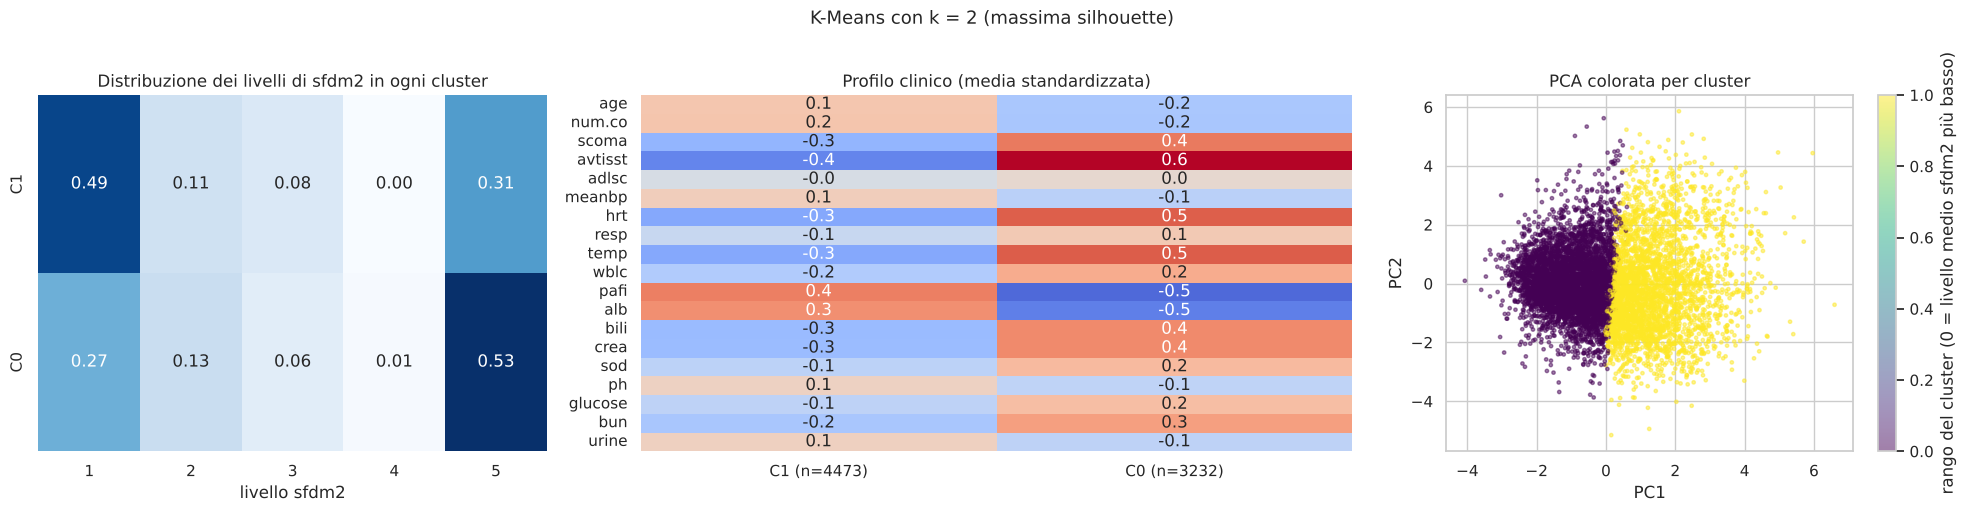

In [36]:
from scipy.stats import kruskal, spearmanr


def analyze_clusters(labels, title):
    labels = np.asarray(labels)
    clusters = np.sort(np.unique(labels))
    mean_level = pd.Series({c: y_ref[labels == c].mean() for c in clusters})
    order = mean_level.sort_values().index.tolist()          # dal meno al più grave
    rank = {c: i for i, c in enumerate(order)}
    H, p_kw = kruskal(*[y_ref[labels == c] for c in clusters])
    rho, p_rho = spearmanr([rank[c] for c in labels], y_ref)

    ct = pd.crosstab(pd.Series(labels, name="cluster"), pd.Series(y_ref, name="livello sfdm2"), normalize="index").loc[order]
    ct.index = [f"C{c}" for c in order]
    sizes = pd.Series(labels).value_counts().loc[order]
    prof = pd.DataFrame(Zc, columns=CLU_FEATURES).groupby(labels).mean().loc[order]
    prof.index = [f"C{c} (n={sizes[c]})" for c in order]
    summary = pd.DataFrame({"pazienti": sizes.values, "livello medio sfdm2": mean_level.loc[order].values.round(2),
                            "mortalità (death)": [clu["death"].values[labels == c].mean().round(3) for c in order]},
                           index=[f"C{c}" for c in order])
    display(summary)
    print(f"Kruskal-Wallis: H = {H:.1f}, p = {p_kw:.2g}   |   Spearman (rango cluster vs livello sfdm2): rho = {rho:.3f}, p = {p_rho:.2g}")
    print(f"ARI = {adjusted_rand_score(y_ref, labels):.3f}, NMI = {normalized_mutual_info_score(y_ref, labels):.3f}")

    fig, axes = plt.subplots(1, 3, figsize=(20, 5), gridspec_kw={"width_ratios": [1, 1.4, 1]})
    sns.heatmap(ct, annot=True, fmt=".2f", cmap="Blues", ax=axes[0], cbar=False)
    axes[0].set_title("Distribuzione dei livelli di sfdm2 in ogni cluster")
    sns.heatmap(prof.T, annot=True, fmt=".1f", cmap="coolwarm", center=0, ax=axes[1], cbar=False)
    axes[1].set_title("Profilo clinico (media standardizzata)")
    scat = axes[2].scatter(P[:, 0], P[:, 1], c=[rank[c] for c in labels], cmap="viridis", s=6, alpha=0.5)
    plt.colorbar(scat, ax=axes[2], label="rango del cluster (0 = livello medio sfdm2 più basso)")
    axes[2].set_title("PCA colorata per cluster")
    axes[2].set_xlabel("PC1"); axes[2].set_ylabel("PC2")
    fig.suptitle(title, y=1.02, fontsize=13)
    plt.tight_layout()
    plt.show()


k_star = int(km_sel["Silhouette"].idxmax())
print(f"k suggerito dalla silhouette per K-Means: {k_star}")
lab_star = KMeans(k_star, n_init=10, random_state=RANDOM_STATE).fit_predict(Zc)
analyze_clusters(lab_star, f"K-Means con k = {k_star} (massima silhouette)")

,pazienti,livello medio sfdm2,mortalità (death)
C4,3035,2.31,0.685
C1,1052,2.77,0.643
C2,1654,2.93,0.644
C0,631,3.77,0.769
C3,1333,3.92,0.818


Kruskal-Wallis: H = 915.8, p = 6.4e-197   |   Spearman (rango cluster vs livello sfdm2): rho = 0.335, p = 8.6e-201
ARI = 0.056, NMI = 0.055


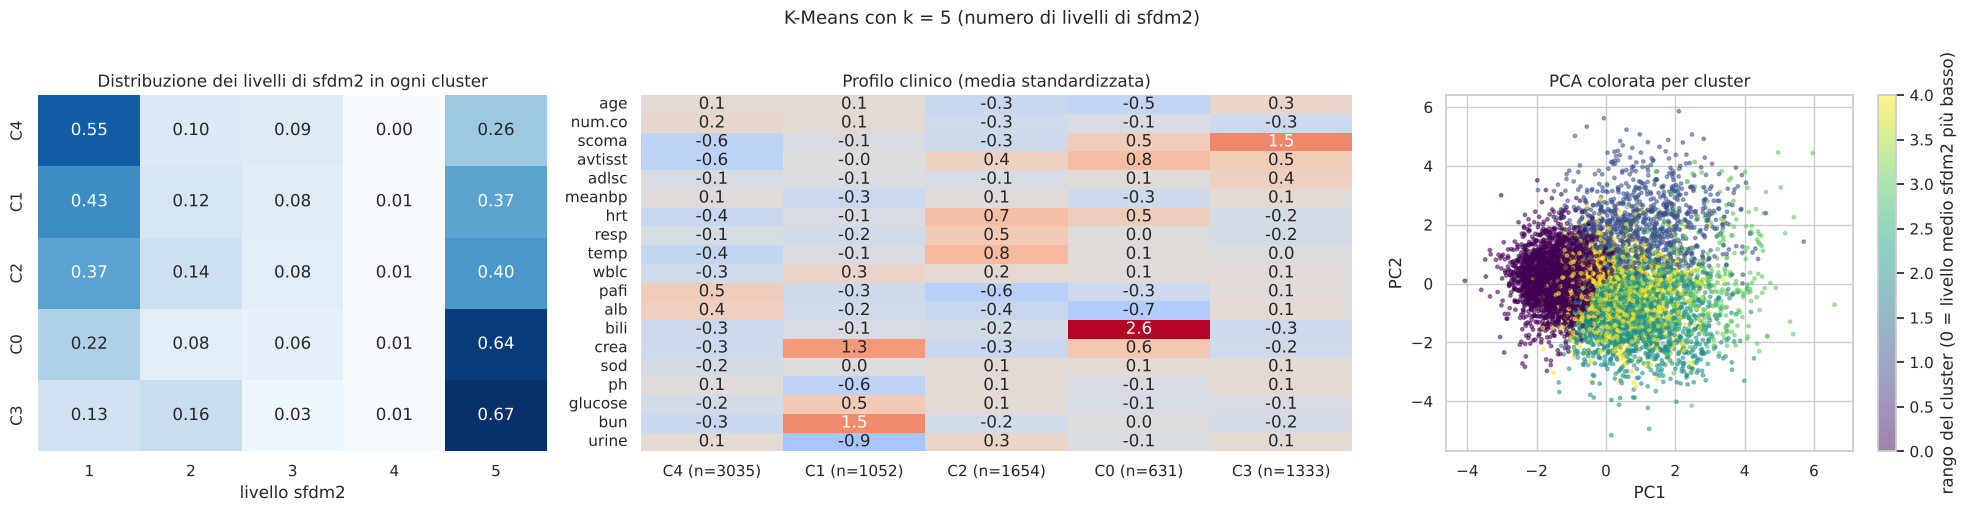

In [37]:
lab5 = all_labels[("K-Means", "euclidea")]
analyze_clusters(lab5, "K-Means con k = 5 (numero di livelli di sfdm2)")

**Commento.**

- **K-Means con k = 2** (silhouette massima, 0.110, comunque bassa). Separa due gruppi lungo la prima componente principale. Il cluster "meno grave" (C1, 4473 pazienti) ha pafi e albumina più alte e frequenza cardiaca, temperatura, bilirubina, creatinina, azotemia e intensità di trattamento più basse; il cluster "più grave" (C0, 3232 pazienti) ha il profilo opposto. Il livello medio di `sfdm2` è 2.53 contro 3.42, la quota di morti entro 2 mesi (livello 5) sale dal 31% al 53% e quella di pazienti senza disabilità (livello 1) scende dal 49% al 27%.
- **K-Means con k = 5.** I cluster hanno un significato clinico riconoscibile, oltre alla gravità. C4 (3035 pazienti) è il gruppo più "sano" (coma e intensità di trattamento bassi, pafi e albumina alte). C1 ha creatinina e azotemia alte e diuresi bassa (profilo compatibile con insufficienza renale). C2 ha frequenza cardiaca, temperatura e frequenza respiratoria più alte e pafi bassa (compatibile con un quadro infettivo o respiratorio acuto). C0 ha bilirubina molto alta (+2.6 deviazioni standard) e albumina bassa (compatibile con insufficienza epatica). C3 è il gruppo con coma (punteggio di coma +1.5 deviazioni standard). Ordinando i cluster per livello medio di `sfdm2` (da 2.31 a 3.92), la quota di morti entro 2 mesi sale dal 26% (C4) al 67% (C3).
- **Una relazione con la gravità esiste, ma è debole.** In entrambe le soluzioni i livelli di `sfdm2` differiscono in modo significativo tra i cluster (Kruskal-Wallis, p < 10⁻¹⁰⁰) e il rango di gravità del cluster è correlato con il livello di `sfdm2` del paziente (ρ di Spearman 0.24 con k = 2 e 0.34 con k = 5). Ma l'accordo è lontano da una partizione "pulita": ARI e NMI sono ≈ 0.05 e in ogni cluster compaiono tutti i livelli di `sfdm2`.

**Risposta alla domanda del task.** Con le sole variabili cliniche i pazienti non formano gruppi netti: è possibile distinguere **due o tre gradi generali di gravità** (e, con k = 5, profili di compromissione d'organo con gravità crescente), ma **non cinque livelli che riproducano `sfdm2`**. La disabilità a 2 mesi dipende anche da fattori che i dati del 3° giorno non contengono (evoluzione clinica, cure ricevute).

## 7. Conclusioni

| Task | Risultato principale |
|---|---|
| **Regressione** (`totcst`) | Il costo di un ricovero è spiegato soprattutto dalla **durata** (`slos`, `hday`) e dall'**intensità del trattamento** (`avtisst`). Una regressione lineare con queste 3 variabili ha R² = 0.72 sul test; la Random Forest ottimizzata con tutte le variabili arriva a R² = 0.785 (errore medio ≈ 9600 \$). Includendo `charges` e `totmcst` si raggiungerebbe 0.93, ma sarebbe "predire il costo con il costo". |
| **Classificazione** (`death`) | Con le informazioni dei primi giorni la ROC-AUC è ≈ 0.78 (Gradient Boosting, regressione logistica e Random Forest sono equivalenti), con balanced accuracy 0.66 alla soglia 0.5 e 0.71 con una soglia scelta sul training. Le variabili più importanti sono tumore/metastasi, età e coma. Le variabili che contengono già l'esito (`hospdead`, `sfdm2`, `d.time`) porterebbero la AUC a 0.86-0.95 e sono state escluse. |
| **Clustering** (`sfdm2`) | I dati clinici non hanno una struttura di cluster netta (silhouette ≤ 0.11, DBSCAN trova un solo cluster). K-Means individua gruppi con profili clinici sensati e livelli di `sfdm2` significativamente diversi (ρ di Spearman fino a 0.34), ma l'accordo con i 5 livelli è debole (NMI 0.055, contro 0.16 di un modello supervisionato). |

### Scelte metodologiche che reggono i risultati

- **Nessuna fuga di informazione dal test set**: split prima di imputazione, scaling e selezione, tutto dentro `Pipeline`; tuning e scelta del modello solo con la cross-validation sul training.
- **Ragionamento sul dominio per ogni task**: variabili che sono già il target (`charges`/`totmcst` per il costo) o ne contengono l'esito (`hospdead`, `sfdm2`, `d.time` per la mortalità) sono state escluse o trattate in scenari separati, e l'effetto di ogni scelta è stato misurato.
- **Metriche adeguate**: per la classificazione ROC-AUC, PR-AUC e balanced accuracy oltre ad accuracy e F1 (classi sbilanciate); per il clustering metriche interne ed esterne, controllando che i punteggi alti non derivino da soluzioni degeneri.
- **Scelte verificate e non assunte**: ad esempio il logaritmo del target della regressione, provato e scartato perché peggiora le previsioni in dollari.

### Limiti

I dati sono osservazionali e risalgono al 1989-1994; molti valori clinici sono mancanti e imputati; alcuni costi sono quasi certamente non registrati; le associazioni trovate (per esempio tra reddito o razza e costo) non sono causali.